# Data Structures & Algorithms: Linked Lists, Stacks and Queues

> **Who is this for?** Beginners who know basic Python (variables, loops, functions, classes) and want to understand how the classic "linear" data structures work inside, plus university students revising for DSA exams and coding interviews.
>
> **What you will learn**
> - How **singly**, **doubly** and **circular linked lists** work, built from scratch as Python classes, and drawn as box-and-arrow diagrams.
> - The famous linked-list interview problems: reverse, cycle detection (Floyd), middle node, merge two sorted lists, remove the n-th node from the end.
> - When to choose an **array** and when to choose a **linked list**.
> - How to build an **LRU cache** in O(1) per operation (and what an **LFU cache** is).
> - **Stacks** (array-based and linked-list-based) and their applications: balanced brackets, the shunting-yard algorithm, postfix evaluation, undo/redo, the call stack, monotonic stacks and the min-stack.
> - **Queues**: simple, circular, priority (a preview of heaps), `collections.deque`, the sliding-window maximum, and queue applications (BFS, scheduling, streams, queue-from-stacks).
>
> **Prerequisites**
> - [Python basics](../../01_Python/01_basic.ipynb) (lists, dictionaries, functions, classes).
> - Big-O notation and recursion: [01 · Complexity Analysis and Recursion](01_complexity_analysis_and_recursion.ipynb).
> - Hash tables (Python `dict`), which the LRU cache relies on: [04 · Hashing](04_hashing.ipynb).
>
> **Time needed:** about 3 to 4 hours (reading + running + practice problems).
>
> **Runs on:** CPU, no API key, no internet. Libraries: Python standard library, NumPy, pandas, matplotlib, networkx.
>
> **Optional track:** this notebook is part of the *university-level fundamentals track*. It is not required for the rest of the course, but it is recommended for BS/MS AI students and for interview preparation.

## Explained simply

A **data structure** is just a way of arranging things so the jobs you do most often are quick. This notebook is about three "line-shaped" arrangements. A **linked list** is like a treasure hunt: every clue tells you where the next clue is hidden, so adding a new clue anywhere is easy, but finding the 50th clue means following 49 clues first. A **stack** is like a pile of plates: you always add to and take from the top, so the last plate in is the first plate out (this is how the "undo" button works). A **queue** is like the line at a coffee shop: the first person to join is the first person served (this is how printers and online-ticket waiting rooms work). Programs, including AI systems, use these three shapes everywhere because each makes one kind of job very fast.

**Tiny example.** You type `c`, `a`, `t` in an editor; each letter goes onto the undo stack: `[c, a, t]`. Press undo: the top item `t` comes off, leaving `ca`. Press undo again: `a` comes off, leaving `c`. Meanwhile, if 3 friends send songs to a shared party queue in the order 🎵A, 🎵B, 🎵C, they play A, then B, then C, never C first.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Linked list | a chain where each item points to the next | browser back/forward history, music playlists, the LRU cache inside LLM servers |
| Stack | last in, first out (pile of plates) | undo/redo, the "back" button, how Python runs function calls |
| Queue | first in, first out (a waiting line) | printer jobs, customer-support tickets, requests waiting for an AI model |

## Table of contents
1. [Setup](#setup)
2. [Linked lists: singly, doubly, circular](#linked-lists)
3. [Classic linked-list problems](#ll-problems)
4. [Arrays vs. linked lists](#arrays-vs-ll)
5. [LRU cache (and LFU, briefly)](#lru)
6. [Stacks and their applications](#stacks)
7. [Queues, circular queues, priority queues and deques](#queues)
8. [Queue applications](#queue-apps)
9. [Complexity summary](#summary)
10. [How this connects to modern AI](#modern-ai)
11. [Recap, practice problems, further reading](#recap)

<a id="setup"></a>
## 1. Setup

> **In plain English:** we load a few standard tools and fix the random seed so every run gives the same numbers.

We only need the standard library plus NumPy, pandas and matplotlib (for tables and pictures). We fix the random seed so that every run of this notebook prints exactly the same numbers.

In [1]:
import random                                   # random test data
import time                                     # simple timings
import math                                     # isclose, log
import re                                       # tokenising arithmetic expressions
import sys                                      # recursion limit
from collections import deque, OrderedDict, Counter, defaultdict   # built-in containers we compare against
import heapq                                    # binary heap (used in the priority-queue preview)
import bisect                                   # sorted-list insertion

import numpy as np                              # numeric arrays
import pandas as pd                             # pretty trace tables
import matplotlib.pyplot as plt                 # drawings and charts
from matplotlib.patches import Rectangle        # boxes for box-and-arrow diagrams

random.seed(42)                                 # reproducible random tests
np.random.seed(42)
pd.set_option("display.width", 120)             # wide tables print on one line
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| pandas", pd.__version__)

Python 3.12.3 | NumPy 2.4.6 | pandas 2.3.3


<a id="linked-lists"></a>
## 2. Linked lists

> **In plain English:** a linked list is a chain of boxes where each box remembers where the next box is.

### 2.1 Intuition: a treasure hunt

Imagine a treasure hunt. Each clue card tells you two things: a piece of the message, and **where the next card is hidden**. To read the 5th card you must start at the first card and follow the hints one by one. In exchange, adding a new card is easy: write it, hide it anywhere, and change one hint to point at it. Nothing else has to move.

A Python `list` is the opposite: it is like seats in a cinema row, numbered 0, 1, 2, ... You can jump straight to seat 57 (fast access), but to squeeze somebody into seat 3 everyone from seat 3 onward must shuffle one seat to the right (slow insertion).

### 2.2 Definitions

- A **node** is a small object holding a **value** (the data) and one or more **references** (pointers) to other nodes.
- A **singly linked list** is a chain of nodes where each node points to the **next** node; the last node points to `None`. We keep a reference to the first node, the **head**, and often also to the last node, the **tail**.
- A **doubly linked list** gives every node a **next** and a **prev** pointer, so we can walk both ways and unlink a node in O(1) if we already hold a reference to it.
- A **circular linked list** makes the last node point back to the first one instead of `None`, so the chain forms a ring.

Box-and-arrow pictures (the first line is a singly list with values 3, 7, 9):

```
singly:     head -> [3|*]--> [7|*]--> [9|/]          (/ means None)

doubly:     None <--[/|3|*] <--> [*|7|*] <--> [*|9|/]--> None
                    prev data next

circular:   head -> [3|*]--> [7|*]--> [9|*]--+
                      ^                      |
                      +----------------------+
```

### 2.3 A worked example by hand: inserting into a singly linked list

Insert value `5` **after** the node holding `3` in `3 -> 7 -> 9`:

| Step | What we do | List afterwards |
|---|---|---|
| 1 | Walk from head until we stand on node `3` (`node = head`) | `3 -> 7 -> 9` |
| 2 | Create `new = Node(5)` | `3 -> 7 -> 9`, `5` floating |
| 3 | `new.next = node.next` (5 now points at 7) | `3 -> 7 -> 9`, `5 -> 7` |
| 4 | `node.next = new` (3 now points at 5) | `3 -> 5 -> 7 -> 9` |

⚠️ **Common mistake:** doing step 4 before step 3. Then `node.next` already points to `5`, so `new.next = node.next` makes `5` point to itself and the rest of the list (`7 -> 9`) is lost.

In [2]:
class Node:
    '''One box of a singly linked list: a value and a pointer to the next box.'''
    def __init__(self, value, next=None):
        self.value = value          # the data stored in this node
        self.next = next            # reference to the next Node, or None at the end

    def __repr__(self):
        return f"Node({self.value})"


class SinglyLinkedList:
    '''A singly linked list with head and tail pointers and a size counter.'''

    def __init__(self, iterable=()):
        self.head = None            # first node (None means the list is empty)
        self.tail = None            # last node, kept so that push_back is O(1)
        self.size = 0               # number of nodes, kept so that len() is O(1)
        for v in iterable:          # convenience: build from any iterable
            self.push_back(v)

    def __len__(self):
        return self.size

    def __iter__(self):             # lets us write `for v in lst` and list(lst)
        node = self.head
        while node is not None:     # walk until we fall off the end
            yield node.value
            node = node.next

    def __repr__(self):             # ASCII box-and-arrow drawing
        return "head -> " + "".join(f"[{v}] -> " for v in self) + "None"

    # ---------- insertion ----------
    def push_front(self, value):                    # O(1)
        self.head = Node(value, self.head)          # new node points at the old head
        if self.tail is None:                       # list was empty: new node is also the tail
            self.tail = self.head
        self.size += 1

    def push_back(self, value):                     # O(1) thanks to the tail pointer
        node = Node(value)
        if self.tail is None:                       # empty list
            self.head = self.tail = node
        else:
            self.tail.next = node                   # old tail points at the new node
            self.tail = node                        # new node becomes the tail
        self.size += 1

    def insert(self, index, value):                 # O(index): we must walk to position index-1
        if not 0 <= index <= self.size:
            raise IndexError("insert index out of range")
        if index == 0:
            return self.push_front(value)
        if index == self.size:
            return self.push_back(value)
        prev = self._node_at(index - 1)             # node just before the insertion point
        prev.next = Node(value, prev.next)          # steps 3 and 4 of the hand example, in the right order
        self.size += 1

    # ---------- access / search ----------
    def _node_at(self, index):                      # O(index)
        node = self.head
        for _ in range(index):
            node = node.next
        return node

    def get(self, index):                           # O(index): no random access in a linked list
        if not 0 <= index < self.size:
            raise IndexError("index out of range")
        return self._node_at(index).value

    def find(self, value):                          # O(n): linear search, returns index or -1
        for i, v in enumerate(self):
            if v == value:
                return i
        return -1

    # ---------- deletion ----------
    def pop_front(self):                            # O(1)
        if self.head is None:
            raise IndexError("pop from empty list")
        node = self.head
        self.head = node.next                       # unlink the first node
        if self.head is None:                       # list became empty: fix the tail too
            self.tail = None
        self.size -= 1
        return node.value

    def delete_at(self, index):                     # O(index)
        if not 0 <= index < self.size:
            raise IndexError("index out of range")
        if index == 0:
            return self.pop_front()
        prev = self._node_at(index - 1)
        node = prev.next
        prev.next = node.next                       # bypass the node
        if node is self.tail:                       # deleting the last node: move the tail back
            self.tail = prev
        self.size -= 1
        return node.value

    def remove(self, value):                        # O(n): delete the first node holding value
        prev, node = None, self.head
        while node is not None and node.value != value:
            prev, node = node, node.next            # keep a trailing pointer
        if node is None:
            return False                            # not found
        if prev is None:
            self.head = node.next                   # removing the head
        else:
            prev.next = node.next                   # bypass the node
        if node is self.tail:
            self.tail = prev
        self.size -= 1
        return True


lst = SinglyLinkedList([3, 7, 9])
print("start:              ", lst)
lst.insert(1, 5);   print("insert(1, 5):       ", lst)
lst.push_front(1);  print("push_front(1):      ", lst)
lst.push_back(11);  print("push_back(11):      ", lst)
print("find(7) ->", lst.find(7), "| find(42) ->", lst.find(42), "| get(2) ->", lst.get(2))
lst.remove(7);      print("remove(7):          ", lst)
lst.delete_at(0);   print("delete_at(0):       ", lst)
lst.delete_at(len(lst) - 1); print("delete_at(last):    ", lst, "| tail =", lst.tail, "| len =", len(lst))

start:               head -> [3] -> [7] -> [9] -> None
insert(1, 5):        head -> [3] -> [5] -> [7] -> [9] -> None
push_front(1):       head -> [1] -> [3] -> [5] -> [7] -> [9] -> None
push_back(11):       head -> [1] -> [3] -> [5] -> [7] -> [9] -> [11] -> None
find(7) -> 3 | find(42) -> -1 | get(2) -> 5
remove(7):           head -> [1] -> [3] -> [5] -> [9] -> [11] -> None
delete_at(0):        head -> [3] -> [5] -> [9] -> [11] -> None
delete_at(last):     head -> [3] -> [5] -> [9] -> None | tail = Node(9) | len = 3


**What just happened?** Every operation only changed a couple of `next` pointers. `insert(1, 5)` walked one step and re-wired two arrows; `push_front` and `push_back` did not walk at all because we keep `head` and `tail`. Deleting the last node needed extra care: the `tail` pointer must move back to the previous node, otherwise it would point at a node that is no longer in the list.

Testing data structures by hand is not enough. Below we run **2,000 random operations** on our list and on a plain Python `list` side by side and assert that they always agree. This *randomised differential testing* is how professionals test data-structure code.

In [3]:
def test_singly_linked_list(n_ops=2000, seed=0):
    rng = random.Random(seed)
    ours, ref = SinglyLinkedList(), []                    # our structure and the reference (built-in list)
    for _ in range(n_ops):
        op = rng.choice(["push_front", "push_back", "insert", "pop_front", "delete_at", "remove", "find", "get"])
        x = rng.randint(0, 20)
        if op == "push_front":
            ours.push_front(x); ref.insert(0, x)
        elif op == "push_back":
            ours.push_back(x); ref.append(x)
        elif op == "insert":
            i = rng.randint(0, len(ref)); ours.insert(i, x); ref.insert(i, x)
        elif op == "pop_front" and ref:
            assert ours.pop_front() == ref.pop(0)
        elif op == "delete_at" and ref:
            i = rng.randrange(len(ref)); assert ours.delete_at(i) == ref.pop(i)
        elif op == "remove":
            found = x in ref
            assert ours.remove(x) == found
            if found: ref.remove(x)
        elif op == "find":
            assert ours.find(x) == (ref.index(x) if x in ref else -1)
        elif op == "get" and ref:
            i = rng.randrange(len(ref)); assert ours.get(i) == ref[i]
        assert list(ours) == ref and len(ours) == len(ref)  # same contents after every step
        assert (ours.tail.value if ours.tail else None) == (ref[-1] if ref else None)   # tail is correct
    return True

print("singly linked list passes randomised test:", all(test_singly_linked_list(seed=s) for s in range(5)))

singly linked list passes randomised test: True


**Complexity of a singly linked list** (n = number of nodes):

| Operation | Time | Why |
|---|---|---|
| `push_front`, `pop_front` | O(1) | only the head pointer changes |
| `push_back` | O(1) | thanks to the tail pointer (O(n) without it) |
| `pop_back` | O(n) | we must find the node *before* the tail, and there is no `prev` pointer |
| `get(i)`, `insert(i)`, `delete_at(i)` | O(i), worst O(n) | we must walk i steps from the head |
| `find(value)` / `remove(value)` | O(n) | linear search |
| Extra space | O(n) | one node object (value + pointer) per element |

### 2.4 Doubly linked list with sentinel nodes

A **sentinel** (or *dummy*) node is a fake node that holds no data and sits permanently at the start (and/or end) of the list. With a sentinel `head` and a sentinel `tail`, every real node always has a real `prev` and `next`, so insertion and deletion never need `if node is None` special cases. This is the trick used by most production implementations.

```
 [HEAD] <--> [1] <--> [2] <--> [3] <--> [TAIL]      empty list:  [HEAD] <--> [TAIL]
```

In [4]:
class DNode:
    '''A node of a doubly linked list.'''
    def __init__(self, value=None):
        self.value = value
        self.prev = None            # pointer to the previous node
        self.next = None            # pointer to the next node


class DoublyLinkedList:
    '''Doubly linked list with two sentinel nodes (head and tail never hold data).'''

    def __init__(self, iterable=()):
        self.head = DNode()                         # sentinel before the first real node
        self.tail = DNode()                         # sentinel after the last real node
        self.head.next, self.tail.prev = self.tail, self.head
        self.size = 0
        for v in iterable:
            self.push_back(v)

    def __len__(self):
        return self.size

    def __iter__(self):                             # forward walk
        node = self.head.next
        while node is not self.tail:
            yield node.value
            node = node.next

    def backwards(self):                            # backward walk: possible only because of prev pointers
        node = self.tail.prev
        while node is not self.head:
            yield node.value
            node = node.prev

    def __repr__(self):
        return "None <- " + " <-> ".join(f"[{v}]" for v in self) + " -> None" if self.size else "None"

    # ---------- the two core helpers: everything else is built on them ----------
    def _insert_between(self, value, before, after):   # O(1)
        node = DNode(value)
        node.prev, node.next = before, after        # new node points at both neighbours
        before.next = node                          # neighbours point back at it
        after.prev = node
        self.size += 1
        return node

    def _unlink(self, node):                        # O(1): needs no search because we hold the node
        node.prev.next = node.next                  # left neighbour skips over node
        node.next.prev = node.prev                  # right neighbour skips back over node
        node.prev = node.next = None                # help catch bugs (dangling node)
        self.size -= 1
        return node.value

    # ---------- public operations ----------
    def push_front(self, value):  return self._insert_between(value, self.head, self.head.next)
    def push_back(self, value):   return self._insert_between(value, self.tail.prev, self.tail)
    def insert_after(self, node, value): return self._insert_between(value, node, node.next)

    def pop_front(self):
        if self.size == 0: raise IndexError("pop from empty list")
        return self._unlink(self.head.next)

    def pop_back(self):                             # O(1) here, O(n) in a singly list
        if self.size == 0: raise IndexError("pop from empty list")
        return self._unlink(self.tail.prev)

    def find(self, value):                          # O(n): returns the node (or None)
        node = self.head.next
        while node is not self.tail:
            if node.value == value:
                return node
            node = node.next
        return None

    def remove(self, value):                        # O(n) search + O(1) unlink
        node = self.find(value)
        if node is None:
            return False
        self._unlink(node)
        return True


d = DoublyLinkedList([1, 2, 3])
print("start:           ", d)
two = d.find(2)                                     # keep a reference to the node holding 2
d.insert_after(two, 99); print("insert_after(2):  ", d)
d._unlink(two);          print("unlink node 2:    ", d, " <- O(1), no search needed")
d.push_front(0); d.push_back(4); print("push both ends:   ", d)
print("forwards: ", list(d), "| backwards:", list(d.backwards()))
print("pop_back ->", d.pop_back(), "| pop_front ->", d.pop_front(), "|", d)

# randomised test against collections.deque (a built-in double-ended queue)
def test_doubly(seed):
    rng = random.Random(seed); ours, ref = DoublyLinkedList(), deque()
    for _ in range(2000):
        op, x = rng.randrange(5), rng.randint(0, 9)
        if op == 0: ours.push_front(x); ref.appendleft(x)
        elif op == 1: ours.push_back(x); ref.append(x)
        elif op == 2 and ref: assert ours.pop_front() == ref.popleft()
        elif op == 3 and ref: assert ours.pop_back() == ref.pop()
        elif op == 4:
            found = x in ref
            assert ours.remove(x) == found
            if found: ref.remove(x)
        assert list(ours) == list(ref) and list(ours.backwards()) == list(reversed(ref))
    return True

print("doubly linked list passes randomised test:", all(test_doubly(s) for s in range(5)))

start:            None <- [1] <-> [2] <-> [3] -> None
insert_after(2):   None <- [1] <-> [2] <-> [99] <-> [3] -> None
unlink node 2:     None <- [1] <-> [99] <-> [3] -> None  <- O(1), no search needed
push both ends:    None <- [0] <-> [1] <-> [99] <-> [3] <-> [4] -> None
forwards:  [0, 1, 99, 3, 4] | backwards: [4, 3, 99, 1, 0]
pop_back -> 4 | pop_front -> 0 | None <- [1] <-> [99] <-> [3] -> None


doubly linked list passes randomised test: True


**What just happened?** Because we held a reference to the node `2`, `_unlink` removed it in O(1) by re-wiring its two neighbours, with no searching. That one property, *"delete a node I already have, in O(1)"*, is exactly what the LRU cache in section 5 needs. The sentinels meant `push_front`, `push_back`, `pop_front` and `pop_back` are all one-liners on top of the same two helpers.

🎓 **Exam / interview tip:** "Why use a doubly linked list instead of a singly linked list?" Answer: O(1) deletion of a given node and O(1) `pop_back`, plus backward traversal, at the cost of one extra pointer per node.

### 2.5 Circular linked list and the Josephus problem

In a **circular singly linked list** the last node points back to the first. It is convenient to store only a `tail` pointer: the head is then simply `tail.next`, so we can add at both the front and the back in O(1). Circular lists model anything that goes round and round: players taking turns, round-robin CPU scheduling, a playlist on repeat.

**Josephus problem:** n people stand in a circle; counting starts at person 0 and every k-th person is removed until one remains. Who survives? Simulating it with a circular list is natural. We will check the answer against the known recurrence J(1) = 0, J(n) = (J(n-1) + k) mod n (people numbered from 0).

In [5]:
class CircularLinkedList:
    '''Circular singly linked list that stores only the tail (head = tail.next).'''

    def __init__(self, iterable=()):
        self.tail = None
        self.size = 0
        for v in iterable:
            self.append(v)

    def __len__(self):
        return self.size

    def __iter__(self):                         # exactly `size` steps, otherwise we would loop forever
        node = self.tail.next if self.tail else None
        for _ in range(self.size):
            yield node.value
            node = node.next

    def __repr__(self):
        if not self.size: return "(empty ring)"
        vals = list(self)
        return " -> ".join(f"[{v}]" for v in vals) + f" -> (back to [{vals[0]}])"

    def prepend(self, value):                   # O(1): insert after the tail, i.e. at the head
        node = Node(value)
        if self.tail is None:
            node.next = node                    # a single node points to itself
            self.tail = node
        else:
            node.next = self.tail.next          # new node points at the old head
            self.tail.next = node               # tail points at the new head
        self.size += 1

    def append(self, value):                    # O(1): prepend, then move the tail forward
        self.prepend(value)
        if self.size > 1:
            self.tail = self.tail.next

    def rotate(self, steps=1):                  # O(steps): the head moves to the back
        for _ in range(steps):
            self.tail = self.tail.next

    def remove_after(self, node):               # O(1): delete node.next
        victim = node.next
        if victim is node:                      # it was the only node
            self.tail = None
        else:
            node.next = victim.next
            if victim is self.tail:
                self.tail = node
        self.size -= 1
        return victim.value

    def find(self, value):                      # O(n)
        for i, v in enumerate(self):
            if v == value:
                return i
        return -1


ring = CircularLinkedList([1, 2, 3, 4])
print(ring)
ring.prepend(0); print("prepend(0):", ring)
ring.rotate(2);  print("rotate(2): ", ring)


def josephus_ring(n, k):
    '''Return (elimination order, survivor) using a circular linked list.'''
    ring = CircularLinkedList(range(n))
    prev = ring.tail                            # the node *before* the current person
    order = []
    while len(ring) > 1:
        for _ in range(k - 1):                  # skip k-1 people
            prev = prev.next
        order.append(ring.remove_after(prev))   # the k-th person leaves
    return order, ring.tail.value


def josephus_formula(n, k):
    j = 0                                       # J(1) = 0
    for m in range(2, n + 1):
        j = (j + k) % m                         # J(m) = (J(m-1) + k) mod m
    return j


order, survivor = josephus_ring(7, 3)
print("n=7, k=3 elimination order:", order, "| survivor:", survivor)
for n in range(1, 60):
    for k in range(1, 8):
        assert josephus_ring(n, k)[1] == josephus_formula(n, k)
print("circular-list simulation matches the Josephus recurrence for all n < 60, k < 8")

[1] -> [2] -> [3] -> [4] -> (back to [1])
prepend(0): [0] -> [1] -> [2] -> [3] -> [4] -> (back to [0])
rotate(2):  [2] -> [3] -> [4] -> [0] -> [1] -> (back to [2])
n=7, k=3 elimination order: [2, 5, 1, 6, 4, 0] | survivor: 3
circular-list simulation matches the Josephus recurrence for all n < 60, k < 8


**What just happened?** With 7 people and k = 3, people leave in the order 2, 5, 1, 6, 4, 0 and person **3** survives. Each removal is O(1) once we are standing on the previous node, so the simulation costs O(n·k) in total. The ring never has an "end", which is why `__iter__` must count `size` steps.

⚠️ **Common mistake:** writing `while node is not None` to walk a circular list. There is no `None`, so the loop never stops. Stop after `size` steps, or when you get back to the starting node.

### 2.6 Drawing the three kinds of list

The function below draws box-and-arrow diagrams with matplotlib, so you can see the pointers.

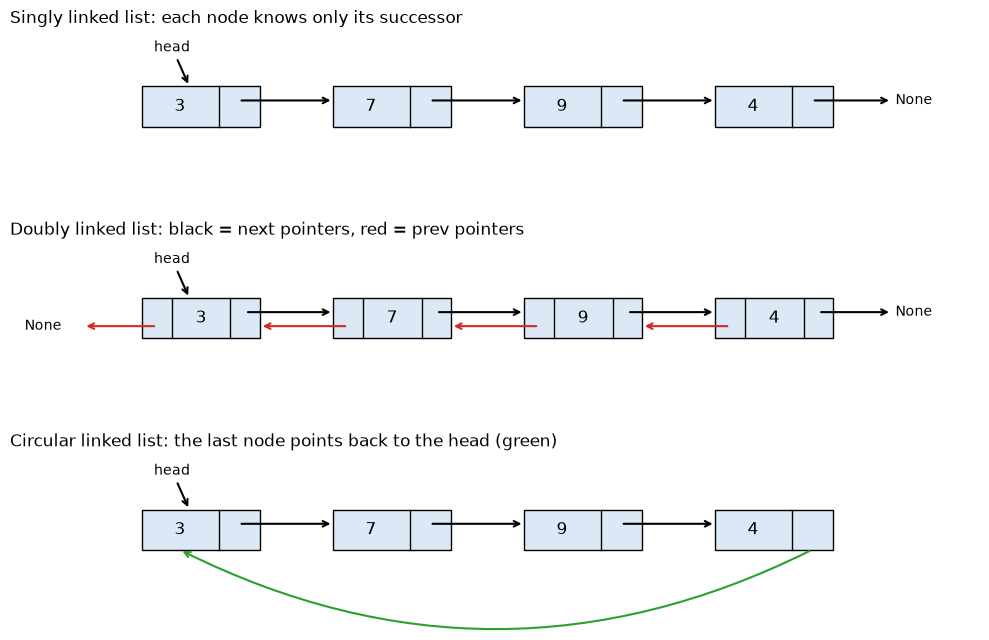

In [6]:
def draw_linked_list(ax, values, kind="singly", title=""):
    '''Draw a singly / doubly / circular linked list as boxes and arrows.'''
    w, h, gap = 1.6, 0.8, 1.0                                      # box width, height, gap between boxes
    xs = [i * (w + gap) for i in range(len(values))]               # left edge of every box
    for x, v in zip(xs, values):
        ax.add_patch(Rectangle((x, 0), w, h, facecolor="#dbe9f6", edgecolor="black"))
        if kind == "doubly":                                       # [prev | data | next]
            for frac in (0.25, 0.75):
                ax.plot([x + w * frac] * 2, [0, h], color="black", lw=1)
            ax.text(x + w * 0.5, h / 2, str(v), ha="center", va="center", fontsize=12)
        else:                                                      # [data | next]
            ax.plot([x + w * 0.65] * 2, [0, h], color="black", lw=1)
            ax.text(x + w * 0.32, h / 2, str(v), ha="center", va="center", fontsize=12)
    arrow = dict(arrowstyle="->", lw=1.5)
    nxt = 0.875 if kind == "doubly" else 0.82                      # centre of the "next" compartment
    for x, x2 in zip(xs, xs[1:]):                                  # forward arrows
        ax.annotate("", xy=(x2, h * 0.65), xytext=(x + w * nxt, h * 0.65), arrowprops=arrow)
        if kind == "doubly":                                       # backward arrows
            ax.annotate("", xy=(x + w, h * 0.3), xytext=(x2 + w * 0.125, h * 0.3), arrowprops=dict(arrow, color="tab:red"))
    end = xs[-1] + w
    if kind in ("singly", "doubly"):
        ax.annotate("", xy=(end + 0.8, h * 0.65), xytext=(xs[-1] + w * nxt, h * 0.65), arrowprops=arrow)
        ax.text(end + 0.85, h * 0.65, "None", va="center", fontsize=10)
    if kind == "doubly":
        ax.annotate("", xy=(-0.8, h * 0.3), xytext=(w * 0.125, h * 0.3), arrowprops=dict(arrow, color="tab:red"))
        ax.text(-1.6, h * 0.3, "None", va="center", fontsize=10)
    if kind == "circular":                                         # last node points back to the first
        ax.annotate("", xy=(w * 0.32, 0), xytext=(xs[-1] + w * nxt, 0),
                    arrowprops=dict(arrow, connectionstyle="arc3,rad=-0.25", color="tab:green"))
    ax.annotate("head", xy=(w * 0.4, h), xytext=(w * 0.1, h + 0.7), arrowprops=arrow, fontsize=10)
    ax.set_xlim(-1.8, end + 2.0); ax.set_ylim(-1.6, h + 1.1)
    ax.set_title(title, loc="left"); ax.axis("off")


fig, axes = plt.subplots(3, 1, figsize=(10, 6.5))
draw_linked_list(axes[0], [3, 7, 9, 4], "singly", "Singly linked list: each node knows only its successor")
draw_linked_list(axes[1], [3, 7, 9, 4], "doubly", "Doubly linked list: black = next pointers, red = prev pointers")
draw_linked_list(axes[2], [3, 7, 9, 4], "circular", "Circular linked list: the last node points back to the head (green)")
plt.tight_layout(); plt.show()

**What just happened?** The three pictures show the only difference between the variants: which pointers each node stores and where the last pointer goes (`None` or back to the head).

| Variant | Pointers per node | Extra abilities | Typical use |
|---|---|---|---|
| Singly | 1 (`next`) | smallest memory | stacks, hash-table buckets (separate chaining), immutable lists in functional languages |
| Doubly | 2 (`prev`, `next`) | O(1) delete of a known node, O(1) both ends, walk backwards | LRU caches, browser history, text editors, `collections.deque` (a doubly linked list of 64-slot blocks in CPython) |
| Circular | 1 or 2 | no end, easy rotation | round-robin scheduling, multiplayer turn order, ring buffers |

<a id="ll-problems"></a>
## 3. Classic linked-list problems

> **In plain English:** these are the classic puzzles (reverse the chain, find a loop, find the middle) that test whether you can re-wire the arrows correctly.

These five problems appear constantly in exams and interviews. They work directly on chains of `Node` objects (a head pointer, no wrapper class), which is how interview platforms present them. Two small helpers convert between Python lists and chains.

In [7]:
def build(values):
    '''Python list -> chain of Nodes; returns the head (or None).'''
    head = None
    for v in reversed(values):          # build back to front so each new node points at the previous head
        head = Node(v, head)
    return head


def to_list(head, limit=10_000):
    '''Chain of Nodes -> Python list (limit protects us if there is an accidental cycle).'''
    out = []
    while head is not None and len(out) < limit:
        out.append(head.value)
        head = head.next
    return out


print(to_list(build([1, 2, 3])), to_list(build([])))

[1, 2, 3] []


### 3.1 Reverse a linked list (iterative and recursive)

**Idea (iterative):** walk the list once and flip every arrow. We need three pointers: `prev` (the already-reversed part), `curr` (the node we are flipping) and `nxt` (saved so we do not lose the rest of the list).

Hand trace on `1 -> 2 -> 3 -> None`:

| Step | prev | curr | nxt saved | after `curr.next = prev` |
|---|---|---|---|---|
| start | None | 1 | | |
| 1 | None | 1 | 2 | `1 -> None` |
| 2 | 1 | 2 | 3 | `2 -> 1 -> None` |
| 3 | 2 | 3 | None | `3 -> 2 -> 1 -> None` |
| end | 3 | None | | new head = prev = 3 |

**Idea (recursive):** reverse everything after the head, then hook the head on at the end: `head.next.next = head; head.next = None`.

In [8]:
def reverse_iterative(head):
    prev, curr = None, head
    rows = []                                   # trace for the table below
    while curr is not None:
        nxt = curr.next                         # 1. remember the rest of the list
        curr.next = prev                        # 2. flip the arrow
        prev, curr = curr, nxt                  # 3. advance both pointers
        rows.append({"prev": str(prev.value), "curr": str(curr.value) if curr else "None", "reversed part": to_list(prev)})
    reverse_iterative.trace = rows              # stash the trace for display
    return prev                                 # prev is the new head


def reverse_recursive(head):
    if head is None or head.next is None:       # base case: empty or one node is already reversed
        return head
    new_head = reverse_recursive(head.next)     # reverse the rest: head.next is now its *last* node
    head.next.next = head                       # hook head after it
    head.next = None                            # head becomes the new tail
    return new_head


print("iterative:", to_list(reverse_iterative(build([1, 2, 3, 4]))))
display(pd.DataFrame(reverse_iterative.trace))
print("recursive:", to_list(reverse_recursive(build([1, 2, 3, 4]))))

rng = random.Random(1)
for _ in range(500):                            # randomised check against Python's slicing
    vals = [rng.randint(0, 99) for _ in range(rng.randint(0, 300))]
    assert to_list(reverse_iterative(build(vals))) == vals[::-1]
    assert to_list(reverse_recursive(build(vals))) == vals[::-1]
print("both reversals agree with vals[::-1] on 500 random lists")

iterative: [4, 3, 2, 1]


,prev,curr,reversed part
0,1,2,[1]
1,2,3,"[2, 1]"
2,3,4,"[3, 2, 1]"
3,4,None,"[4, 3, 2, 1]"


recursive: [4, 3, 2, 1]


both reversals agree with vals[::-1] on 500 random lists


**What just happened?** Both versions return `4 -> 3 -> 2 -> 1`. The iterative one is O(n) time and **O(1)** extra space; the recursive one is O(n) time but **O(n)** space for the call stack (one frame per node). With Python's default recursion limit of 1,000 frames, the recursive version crashes on long lists; we look at this in section 6.5.

### 3.2 Detect a cycle: Floyd's tortoise and hare

A bug (or a deliberately circular structure) can make a list loop back on itself, forming a shape like the Greek letter ρ (rho). Walking it naively never ends.

**Floyd's algorithm:** move a **slow** pointer one step and a **fast** pointer two steps at a time. If there is no cycle, `fast` reaches `None`. If there is a cycle, the fast pointer gains one node per step on the slow one *inside the loop*, so it must eventually land on the same node.

**Finding where the cycle starts.** Let μ = number of steps from the head to the cycle start, λ = cycle length, and suppose they meet a steps into the cycle. Slow walked μ + a, fast walked 2(μ + a), and the extra μ + a steps are whole laps: μ + a = m·λ. So walking μ more steps from the meeting point lands exactly on the cycle start (a + μ ≡ 0 mod λ). Therefore: put one pointer back at the head, keep one at the meeting point, move both one step at a time, and they meet at the cycle start.

Time O(n), extra space **O(1)**. (A hash set of visited nodes also works, but uses O(n) memory; we use it as our reference.)

In [9]:
def floyd_cycle(head):
    '''Return (meeting_node, cycle_start_node) or (None, None) if the list is acyclic.'''
    slow = fast = head
    while fast is not None and fast.next is not None:
        slow = slow.next                        # tortoise: 1 step
        fast = fast.next.next                   # hare: 2 steps
        if slow is fast:                        # they met inside the cycle
            meet = slow
            p = head                            # phase 2: one pointer from the head ...
            while p is not slow:                # ... one from the meeting point, both 1 step at a time
                p, slow = p.next, slow.next
            return meet, p                      # they meet at the start of the cycle
    return None, None


def cycle_start_with_set(head):                 # reference solution: O(n) memory
    seen = set()
    while head is not None:
        if id(head) in seen:
            return head
        seen.add(id(head))
        head = head.next
    return None


def build_with_cycle(n, pos):
    '''Build 0 -> 1 -> ... -> n-1 and link the last node back to node `pos` (pos=-1: no cycle).'''
    nodes = [Node(i) for i in range(n)]
    for a, b in zip(nodes, nodes[1:]):
        a.next = b
    if pos >= 0:
        nodes[-1].next = nodes[pos]
    return nodes[0] if nodes else None


head = build_with_cycle(10, 3)                  # 0..9 with 9 -> 3
meet, start = floyd_cycle(head)
print("meeting node:", meet.value, "| cycle starts at:", start.value)

rng = random.Random(7)
for _ in range(2000):
    n = rng.randint(1, 60)
    pos = rng.choice([-1, rng.randrange(n)])
    h = build_with_cycle(n, pos)
    _, s = floyd_cycle(h)
    assert s is cycle_start_with_set(h)         # same node object (or both None)
print("Floyd agrees with the hash-set method on 2000 random lists (with and without cycles)")

meeting node: 7 | cycle starts at: 3


Floyd agrees with the hash-set method on 2000 random lists (with and without cycles)


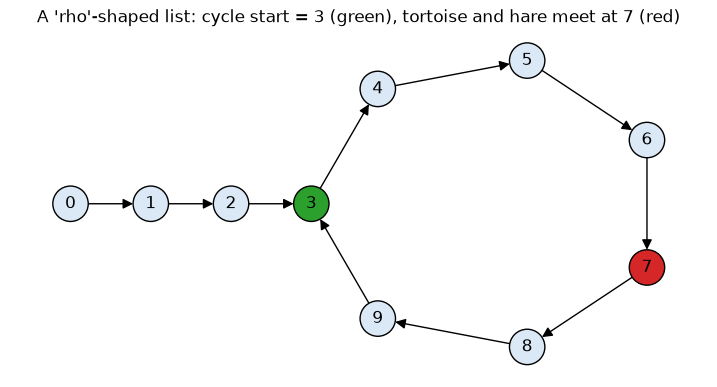

In [10]:
import networkx as nx                           # used only for drawing the rho shape

n, pos = 10, 3
G = nx.DiGraph([(i, i + 1) for i in range(n - 1)] + [(n - 1, pos)])
layout = {i: (i, 0) for i in range(pos)}        # the straight "tail" of the rho
ring_nodes = list(range(pos, n))
for j, v in enumerate(ring_nodes):              # place the cycle on a circle
    ang = math.pi - 2 * math.pi * j / len(ring_nodes)
    layout[v] = (pos + 2.2 + 2.2 * math.cos(ang), 2.2 * math.sin(ang))
colours = ["tab:green" if v == start.value else "tab:red" if v == meet.value else "#dbe9f6" for v in G]
fig, ax = plt.subplots(figsize=(9, 4.5))
nx.draw_networkx(G, layout, node_color=colours, node_size=650, edgecolors="black", arrowsize=15, ax=ax)
ax.set_title(f"A 'rho'-shaped list: cycle start = {start.value} (green), tortoise and hare meet at {meet.value} (red)")
ax.axis("off"); plt.show()

**What just happened?** For the list 0 → 1 → ... → 9 → 3 we have μ = 3 (nodes 0, 1, 2 before the loop) and λ = 7 (nodes 3 to 9). The tortoise and hare met at node 7, which is a = 4 steps into the cycle, and indeed μ + a = 7 is a whole number of laps. Walking μ = 3 more steps from node 7 (to 8, 9, then 3) lands on the cycle start, exactly as the proof promised, and the pointer restarted at the head also needs 3 steps (0 → 1 → 2 → 3). The randomised test confirms the algorithm on 2,000 lists.

🎓 **Exam / interview tip:** the follow-ups are "find the cycle length" (after meeting, walk one pointer round until it returns: λ steps) and "why does fast move 2 and not 3?" (with speed 2 the gap shrinks by exactly one per step, so the hare cannot jump over the tortoise).

### 3.3 Find the middle node

Same slow/fast trick: when `fast` reaches the end, `slow` is halfway. For an even length this returns the **second** of the two middle nodes (the LeetCode 876 convention); start `fast = head.next` if you want the first one.

### 3.4 Merge two sorted lists

Use a **dummy** node so the code never has to special-case "which list provides the first node". Repeatedly attach the smaller front node. O(n + m) time, O(1) extra space (we re-use the existing nodes).

### 3.5 Remove the n-th node from the end

Move a `fast` pointer n + 1 steps ahead of a `slow` pointer that starts on a dummy node. When `fast` falls off the end, `slow` is just before the node to delete. One pass, O(L) time, O(1) space.

In [11]:
def middle_node(head):
    slow = fast = head
    while fast is not None and fast.next is not None:
        slow, fast = slow.next, fast.next.next   # fast covers twice the distance
    return slow


def merge_sorted(a, b):
    dummy = tail = Node(None)                    # dummy start, tail = last node of the merged list
    while a is not None and b is not None:
        if a.value <= b.value:                   # <= keeps equal items from `a` first (stable)
            tail.next, a = a, a.next
        else:
            tail.next, b = b, b.next
        tail = tail.next
    tail.next = a if a is not None else b        # attach whatever is left
    return dummy.next


def remove_nth_from_end(head, n):
    dummy = Node(None, head)                     # dummy handles "remove the head" with no special case
    fast = slow = dummy
    for _ in range(n + 1):                       # open a gap of n+1 nodes
        fast = fast.next
    while fast is not None:                      # move both until fast falls off the end
        fast, slow = fast.next, slow.next
    slow.next = slow.next.next                   # slow is right before the target: bypass it
    return dummy.next


print("middle of [1..5]:", middle_node(build([1, 2, 3, 4, 5])).value, "| middle of [1..6]:", middle_node(build([1, 2, 3, 4, 5, 6])).value)
print("merge [1,4,6] + [2,3,7]:", to_list(merge_sorted(build([1, 4, 6]), build([2, 3, 7]))))
print("remove 2nd from end of [1..5]:", to_list(remove_nth_from_end(build([1, 2, 3, 4, 5]), 2)))

rng = random.Random(3)
for _ in range(1000):
    vals = [rng.randint(0, 50) for _ in range(rng.randint(1, 40))]
    assert middle_node(build(vals)).value == vals[len(vals) // 2]
    a = sorted(rng.randint(0, 50) for _ in range(rng.randint(0, 20)))
    b = sorted(rng.randint(0, 50) for _ in range(rng.randint(0, 20)))
    assert to_list(merge_sorted(build(a), build(b))) == sorted(a + b)
    k = rng.randint(1, len(vals))
    expected = vals[:len(vals) - k] + vals[len(vals) - k + 1:]
    assert to_list(remove_nth_from_end(build(vals), k)) == expected
print("middle, merge and remove-nth-from-end pass 1000 random tests each")

middle of [1..5]: 3 | middle of [1..6]: 4
merge [1,4,6] + [2,3,7]: [1, 2, 3, 4, 6, 7]
remove 2nd from end of [1..5]: [1, 2, 3, 5]


middle, merge and remove-nth-from-end pass 1000 random tests each


**What just happened?** The middle of `[1..5]` is 3 and of `[1..6]` is 4 (the second middle). The merge interleaved the two sorted lists into `[1, 2, 3, 4, 6, 7]` and removing the 2nd node from the end of `[1..5]` deleted `4`. All three were checked against plain Python list operations on 1,000 random inputs.

⚠️ **Common mistake:** forgetting the dummy node in `remove_nth_from_end`, which then crashes (or silently fails) when n equals the list length, i.e. when the head itself must be removed.

| Problem | Technique | Time | Extra space |
|---|---|---|---|
| Reverse | three pointers / recursion | O(n) | O(1) / O(n) stack |
| Detect cycle + start | Floyd (slow/fast) | O(n) | O(1) |
| Middle | slow/fast | O(n) | O(1) |
| Merge two sorted | dummy node | O(n + m) | O(1) |
| Remove n-th from end | two pointers with a gap | O(n) | O(1) |

<a id="arrays-vs-ll"></a>
## 4. Arrays vs. linked lists

> **In plain English:** arrays are best when you jump to positions a lot; linked lists are best when you insert and delete in the middle a lot.

A Python `list` is a **dynamic array**: one contiguous block of memory holding references, which grows by over-allocating (so `append` is *amortised* O(1)).

| | Dynamic array (Python `list`) | Singly linked list | Doubly linked list |
|---|---|---|---|
| Access `x[i]` | **O(1)** (address arithmetic) | O(i) | O(min(i, n-i)) |
| Insert/delete at front | O(n) (shift everything) | **O(1)** | **O(1)** |
| Insert/delete at back | amortised **O(1)** | O(1) insert with tail, O(n) delete | **O(1)** |
| Insert/delete in the middle, position known | O(n) shifting | O(1) after the node *before* it | **O(1)** given the node |
| Search unsorted | O(n) | O(n) | O(n) |
| Binary search when sorted | **O(log n)** | not possible (no random access) | not possible |
| Memory per element | 1 reference (+ some spare capacity) | value + 1 pointer + object header | value + 2 pointers + object header |
| CPU cache friendliness | excellent (contiguous) | poor (nodes scattered in memory) | poor |

🎓 **Exam / interview tip:** Big-O is not the whole story. Because of CPU caches, arrays usually beat linked lists in practice even for some operations where the linked list has a better Big-O. Choose a linked list when you need O(1) insertion/removal at known positions *and* you keep references to nodes (LRU cache, schedulers), not "just because inserting is O(1)".

Let us measure two operations whose Big-O differs. (Timings depend on your computer, so we only look at the *shape* of the curves. We take the best of 3 runs with Python's garbage collector paused, which removes most of the noise.)

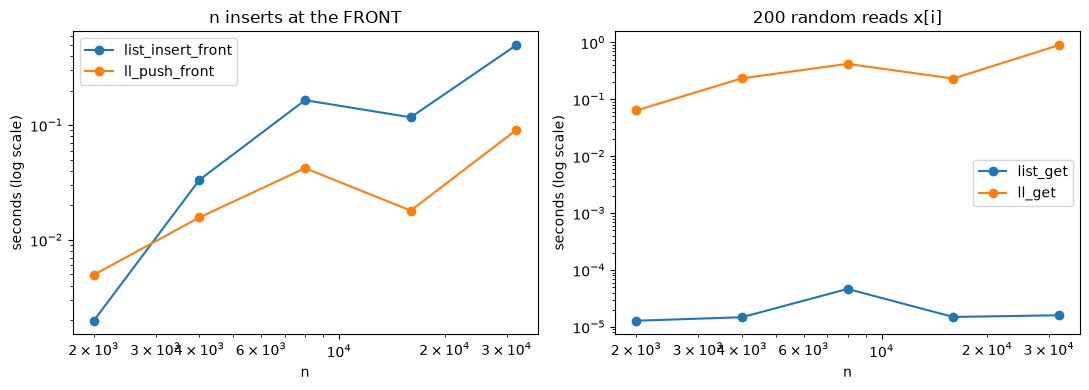

slow-down factor when n grows 16x:
 list_insert_front    252.1
ll_push_front         18.3
list_get               1.2
ll_get                14.1


In [12]:
import gc

def best_of(fn, repeats=3):
    '''Run fn() several times with the garbage collector paused; return the fastest time.'''
    times = []
    for _ in range(repeats):
        gc.disable()
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
        gc.enable()
    return min(times)

def list_front_inserts(n):
    arr = []
    for i in range(n): arr.insert(0, i)                 # array: every insert shifts all elements
    return arr

def ll_front_inserts(n):
    ll = SinglyLinkedList()
    for i in range(n): ll.push_front(i)                 # linked list: O(1) per insert
    return ll

sizes = [2_000, 4_000, 8_000, 16_000, 32_000]
rows = []
for n in sizes:
    t_arr_front = best_of(lambda: list_front_inserts(n))
    t_ll_front = best_of(lambda: ll_front_inserts(n))
    arr, ll = list_front_inserts(n), ll_front_inserts(n)
    idx = [random.randrange(n) for _ in range(200)]     # 200 random positions
    t_arr_get = best_of(lambda: [arr[i] for i in idx])  # array: O(1) jump
    t_ll_get = best_of(lambda: [ll.get(i) for i in idx])   # linked list: walk i steps
    rows.append(dict(n=n, list_insert_front=t_arr_front, ll_push_front=t_ll_front, list_get=t_arr_get, ll_get=t_ll_get))

timing = pd.DataFrame(rows).set_index("n")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
timing[["list_insert_front", "ll_push_front"]].plot(ax=axes[0], marker="o", logx=True, logy=True)
axes[0].set_title("n inserts at the FRONT"); axes[0].set_xlabel("n"); axes[0].set_ylabel("seconds (log scale)")
timing[["list_get", "ll_get"]].plot(ax=axes[1], marker="o", logx=True, logy=True)
axes[1].set_title("200 random reads x[i]"); axes[1].set_xlabel("n"); axes[1].set_ylabel("seconds (log scale)")
plt.tight_layout(); plt.show()

growth = timing.iloc[-1] / timing.iloc[0]               # how much slower when n grows 16x
print("slow-down factor when n grows 16x:\n", growth.round(1).to_string())

**What just happened?** When n grows 16×, Big-O predicts these slow-down factors:
- *n front inserts into a Python list*: Θ(n²) in total, so about 16² = **256×** (usually somewhat less in practice, because the shifting is a very fast `memmove` in C);
- *n front inserts into our linked list*: Θ(n) in total, so about **16×**;
- *200 random reads from the list*: O(1) each, so about **1×** (flat);
- *200 random reads from the linked list*: O(n) each, so about **16×**.

Compare these with the measured factors printed above. Real timings are noisy (other programs, CPU caches, memory allocation), so expect the right *ordering* and *trend* (the quadratic curve is the steepest; list reads stay flat) rather than exact numbers. Plotting on log-log axes helps: a straight line with slope 2 means quadratic, slope 1 means linear, slope 0 means constant.

Notice also that for small n the gap is small (the Python list may even win), because the list's shifting runs in optimised C while our linked list runs in Python. That is the constant-factor effect hidden by Big-O.

<a id="lru"></a>
## 5. LRU cache: a doubly linked list + a hash map

> **In plain English:** an LRU cache keeps the most recently used items close at hand and throws away the one you have not touched for the longest time.

### 5.1 Intuition

Your desk has room for only 3 books. When you need a 4th, you put back the book you have **not used for the longest time**. That policy is **LRU: Least Recently Used** eviction. It is used in CPU caches, operating-system page caches, web caches, database buffer pools, `functools.lru_cache`, and caches of embeddings or LLM responses.

**Definition.** An **LRU cache** with capacity C supports
- `get(key)`: return the value (or -1 if absent) and mark the key as *most recently used*;
- `put(key, value)`: insert/update the key and mark it most recently used; if the cache now holds more than C keys, evict the **least recently used** one.

Goal: **both operations in O(1)**.

### 5.2 The design

- A **hash map** (`dict`) gives O(1) average lookup `key -> node` (see [04 · Hashing](04_hashing.ipynb) for how dictionaries achieve this).
- A **doubly linked list** keeps keys in recency order: most recent next to the `head` sentinel, least recent next to the `tail` sentinel. Moving a node to the front and removing the last node are both O(1) **because we already hold the node** (found through the dict) and the list is doubly linked.

```
 dict: {1: o, 3: o, 4: o}           each o is a pointer into the list
                |     |     |
 [HEAD] <--> [4:d] <--> [3:c] <--> [1:a] <--> [TAIL]
          most recent             least recent -> evicted next
```

Hand trace (capacity 2, the classic LeetCode 146 example):

| Operation | Result | Cache order (most → least recent) | Note |
|---|---|---|---|
| put(1, 1) | | 1 | |
| put(2, 2) | | 2, 1 | |
| get(1) | 1 | 1, 2 | 1 becomes most recent |
| put(3, 3) | | 3, 1 | evicts 2 |
| get(2) | -1 | 3, 1 | miss |
| put(4, 4) | | 4, 3 | evicts 1 |
| get(1) | -1 | 4, 3 | miss |
| get(3) | 3 | 3, 4 | |
| get(4) | 4 | 4, 3 | |

In [13]:
class LRUNode:
    def __init__(self, key=None, value=None):
        self.key, self.value = key, value       # we store the key too, so eviction can delete it from the dict
        self.prev = self.next = None


class LRUCache:
    '''O(1) get/put LRU cache: dict for lookup + doubly linked list for recency order.'''

    def __init__(self, capacity):
        self.capacity = capacity
        self.map = {}                           # key -> LRUNode
        self.head, self.tail = LRUNode(), LRUNode()   # sentinels: head.next = most recent, tail.prev = least recent
        self.head.next, self.tail.prev = self.tail, self.head

    def _remove(self, node):                    # O(1) unlink
        node.prev.next, node.next.prev = node.next, node.prev

    def _add_front(self, node):                 # O(1) insert right after the head sentinel
        node.prev, node.next = self.head, self.head.next
        self.head.next.prev = node
        self.head.next = node

    def get(self, key):
        node = self.map.get(key)                # O(1) average dict lookup
        if node is None:
            return -1                           # cache miss
        self._remove(node); self._add_front(node)   # mark as most recently used
        return node.value

    def put(self, key, value):
        if self.capacity <= 0:
            return
        node = self.map.get(key)
        if node is not None:                    # update an existing key
            node.value = value
            self._remove(node); self._add_front(node)
            return
        node = LRUNode(key, value)              # brand-new key
        self.map[key] = node
        self._add_front(node)
        if len(self.map) > self.capacity:       # over capacity: evict the least recently used
            lru = self.tail.prev
            self._remove(lru)
            del self.map[lru.key]

    def order(self):                            # keys from most to least recent (for display only)
        out, node = [], self.head.next
        while node is not self.tail:
            out.append(node.key); node = node.next
        return out


cache, rows = LRUCache(2), []
script = [("put", 1, 1), ("put", 2, 2), ("get", 1), ("put", 3, 3), ("get", 2), ("put", 4, 4), ("get", 1), ("get", 3), ("get", 4)]
for op, *args in script:
    res = getattr(cache, op)(*args)
    rows.append({"operation": f"{op}({', '.join(map(str, args))})", "result": "" if res is None else res, "order (most -> least recent)": cache.order()})
display(pd.DataFrame(rows))

,operation,result,order (most -> least recent)
0,"put(1, 1)",,[1]
1,"put(2, 2)",,"[2, 1]"
2,get(1),1,"[1, 2]"
3,"put(3, 3)",,"[3, 1]"
4,get(2),-1,"[3, 1]"
5,"put(4, 4)",,"[4, 3]"
6,get(1),-1,"[4, 3]"
7,get(3),3,"[3, 4]"
8,get(4),4,"[4, 3]"


**What just happened?** The table matches the hand trace exactly: `put(3, 3)` evicted key 2 and `put(4, 4)` evicted key 1. Every operation did one dictionary lookup and a constant number of pointer changes, so both `get` and `put` are **O(1)** (average, because dict lookups are O(1) on average). Space is O(C).

### 5.3 The same thing with `OrderedDict`

Python's `collections.OrderedDict` is itself a dict plus a doubly linked list (that is how CPython implements it), and it exposes exactly the two operations we need: `move_to_end(key)` and `popitem(last=False)`. In real code you would use it (or `functools.lru_cache` for memoising functions). Below we check that our class, the `OrderedDict` version and a slow but obviously-correct list-based version agree on thousands of random operations.

In [14]:
class LRUCacheOD:
    def __init__(self, capacity):
        self.capacity, self.data = capacity, OrderedDict()
    def get(self, key):
        if key not in self.data:
            return -1
        self.data.move_to_end(key)              # most recent goes to the end
        return self.data[key]
    def put(self, key, value):
        if self.capacity <= 0:
            return
        if key in self.data:
            self.data.move_to_end(key)
        self.data[key] = value
        if len(self.data) > self.capacity:
            self.data.popitem(last=False)       # pop from the front = least recently used


class LRUBrute:                                 # O(C) per operation, but obviously correct
    def __init__(self, capacity):
        self.capacity, self.items = capacity, []   # list of [key, value], most recent LAST
    def get(self, key):
        for i, (k, v) in enumerate(self.items):
            if k == key:
                self.items.append(self.items.pop(i)); return v
        return -1
    def put(self, key, value):
        if self.capacity <= 0: return
        self.items = [kv for kv in self.items if kv[0] != key] + [[key, value]]
        if len(self.items) > self.capacity:
            self.items.pop(0)


rng = random.Random(11)
for trial in range(200):
    cap = rng.randint(0, 6)
    caches = [LRUCache(cap), LRUCacheOD(cap), LRUBrute(cap)]
    for _ in range(300):
        key = rng.randint(0, 9)
        if rng.random() < 0.5:
            results = {c.get(key) for c in caches}
            assert len(results) == 1            # all three return the same answer
        else:
            val = rng.randint(0, 999)
            for c in caches: c.put(key, val)
    assert caches[0].order() == list(reversed(caches[1].data))   # same recency order
print("LRUCache == OrderedDict version == brute force on 200 x 300 random operations")

LRUCache == OrderedDict version == brute force on 200 x 300 random operations


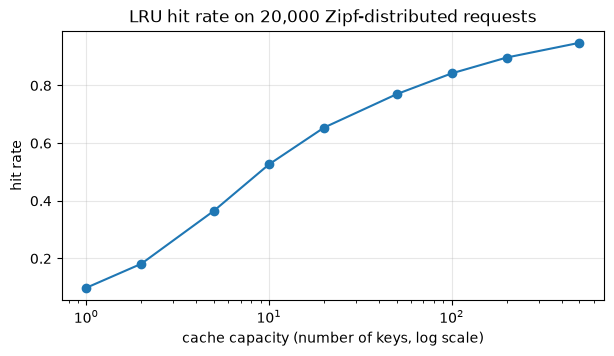

{1: 0.098, 2: 0.181, 5: 0.366, 10: 0.526, 20: 0.654, 50: 0.77, 100: 0.842, 200: 0.897, 500: 0.948}
fib(80) = 23416728348467685 | CacheInfo(hits=78, misses=81, maxsize=128, currsize=81)


In [15]:
# How big should a cache be? Hit rate under a skewed ("a few keys are popular") access pattern.
rng = np.random.default_rng(0)
requests = np.minimum(rng.zipf(1.3, size=20_000), 1_000)   # Zipf: key 1 is very popular, key 1000 is rare
capacities = [1, 2, 5, 10, 20, 50, 100, 200, 500]
hit_rates = []
for cap in capacities:
    c, hits = LRUCacheOD(cap), 0
    for key in requests:
        if c.get(key) != -1: hits += 1          # hit
        else: c.put(key, True)                  # miss: fetch and store
    hit_rates.append(hits / len(requests))

plt.figure(figsize=(7, 3.5))
plt.semilogx(capacities, hit_rates, marker="o")
plt.xlabel("cache capacity (number of keys, log scale)"); plt.ylabel("hit rate")
plt.title("LRU hit rate on 20,000 Zipf-distributed requests"); plt.grid(alpha=0.3); plt.show()
print({c: round(h, 3) for c, h in zip(capacities, hit_rates)})

from functools import lru_cache                  # the standard-library LRU for memoising functions
@lru_cache(maxsize=128)
def fib(n):
    return n if n < 2 else fib(n - 1) + fib(n - 2)
print("fib(80) =", fib(80), "|", fib.cache_info())

**What just happened?** Under a skewed workload a small cache already catches a large share of requests: the printed dictionary shows the hit rate climbing steeply for the first few dozen slots and then flattening, the classic "diminishing returns" curve that engineers use to size caches. `functools.lru_cache` turned the exponential-time recursive Fibonacci into a linear-time one (`hits=78, misses=81`).

### 5.4 LFU cache, briefly

**LFU (Least Frequently Used)** evicts the key with the **smallest access count**; ties are broken by evicting the least recently used among them. It keeps "always popular" items better than LRU, but it adapts slowly when popularity changes (an item that was hot yesterday keeps a high count).

The O(1) design (LeetCode 460) keeps:
- `key -> (value, freq)`,
- `freq -> OrderedDict of keys` (each bucket in LRU order),
- `min_freq`, the smallest frequency currently present.

On every access a key moves from bucket `f` to bucket `f + 1`; if bucket `min_freq` becomes empty, `min_freq` increases by one. A brand-new key always resets `min_freq = 1`.

In [16]:
class LFUCache:
    def __init__(self, capacity):
        self.capacity = capacity
        self.vals = {}                              # key -> value
        self.freq = {}                              # key -> access count
        self.buckets = defaultdict(OrderedDict)     # count -> keys with that count, in LRU order
        self.min_freq = 0

    def _touch(self, key):                          # move key from bucket f to bucket f+1
        f = self.freq[key]
        del self.buckets[f][key]
        if not self.buckets[f]:
            del self.buckets[f]
            if self.min_freq == f:
                self.min_freq = f + 1
        self.freq[key] = f + 1
        self.buckets[f + 1][key] = None

    def get(self, key):
        if key not in self.vals:
            return -1
        self._touch(key)
        return self.vals[key]

    def put(self, key, value):
        if self.capacity <= 0:
            return
        if key in self.vals:
            self.vals[key] = value; self._touch(key); return
        if len(self.vals) >= self.capacity:         # evict: least frequent, then least recent
            victim, _ = self.buckets[self.min_freq].popitem(last=False)
            if not self.buckets[self.min_freq]:
                del self.buckets[self.min_freq]
            del self.vals[victim], self.freq[victim]
        self.vals[key], self.freq[key] = value, 1
        self.buckets[1][key] = None
        self.min_freq = 1


class LFUBrute:                                      # O(C) eviction by scanning: (count, last_used) is minimal
    def __init__(self, capacity):
        self.capacity, self.data, self.clock = capacity, {}, 0   # key -> [value, count, last_used]
    def get(self, key):
        self.clock += 1
        if key not in self.data: return -1
        rec = self.data[key]; rec[1] += 1; rec[2] = self.clock
        return rec[0]
    def put(self, key, value):
        self.clock += 1
        if self.capacity <= 0: return
        if key in self.data:
            rec = self.data[key]; rec[0] = value; rec[1] += 1; rec[2] = self.clock; return
        if len(self.data) >= self.capacity:
            victim = min(self.data, key=lambda k: (self.data[k][1], self.data[k][2]))
            del self.data[victim]
        self.data[key] = [value, 1, self.clock]


rng = random.Random(5)
for trial in range(200):
    cap = rng.randint(0, 5)
    a, b = LFUCache(cap), LFUBrute(cap)
    for _ in range(300):
        key = rng.randint(0, 8)
        if rng.random() < 0.5:
            assert a.get(key) == b.get(key)
        else:
            v = rng.randint(0, 99); a.put(key, v); b.put(key, v)
print("LFUCache agrees with the brute-force LFU on 200 x 300 random operations")

LFUCache agrees with the brute-force LFU on 200 x 300 random operations


| Policy | Evicts | Strength | Weakness |
|---|---|---|---|
| FIFO | oldest *inserted* | trivial (a queue) | ignores usage |
| LRU | least *recently* used | adapts quickly, O(1) | one big scan can flush the cache |
| LFU | least *frequently* used | keeps long-term favourites | slow to forget old favourites |

🎓 **Exam / interview tip:** "Design an LRU cache" is one of the most frequently asked design-a-data-structure questions. The expected answer is exactly *hash map + doubly linked list*, with the reasons: the map gives O(1) lookup, the doubly linked list gives O(1) move-to-front and O(1) eviction, and nodes store their key so that eviction can delete the dict entry.

<a id="stacks"></a>
## 6. Stacks

> **In plain English:** a stack is a pile: you only ever add to or take from the top.

### 6.1 Intuition and definition

A pile of plates: you put a plate on **top** and you take the plate from the **top**. The last plate in is the first plate out.

A **stack** is a collection with **LIFO** (Last In, First Out) order, supporting:
- `push(x)`: put x on top, O(1);
- `pop()`: remove and return the top item, O(1) (error if empty: **stack underflow**);
- `peek()` / `top()`: look at the top item without removing it, O(1);
- `is_empty()`, `len()`.

Two classic implementations:
1. **Array-based:** an array plus an index `top`. When the array is full, allocate one twice as big and copy (dynamic array). Push is **amortised O(1)**: n pushes cause at most about 2n element copies in total.
2. **Linked-list-based:** push and pop at the head of a singly linked list. Every operation is worst-case O(1), but each item costs a node object.

```
push 1, push 2, push 3, pop -> 3
 |   |    |   |    | 3 |    |   |
 |   |    | 2 |    | 2 |    | 2 |
 | 1 |    | 1 |    | 1 |    | 1 |
 +---+    +---+    +---+    +---+
```

In [17]:
class ArrayStack:
    '''Stack on a fixed-size array that doubles when full (and halves when 1/4 full).'''

    def __init__(self, capacity=2):
        self._data = [None] * capacity          # pretend this is a raw, fixed-size array
        self._top = 0                           # number of items = index of the next free slot
        self.copies = 0                         # count element copies to see the amortised cost

    def _resize(self, new_cap):
        new = [None] * new_cap                  # allocate a new array ...
        for i in range(self._top):              # ... and copy the items across (O(n))
            new[i] = self._data[i]
        self.copies += self._top
        self._data = new

    def push(self, x):
        if self._top == len(self._data):        # full: grow geometrically
            self._resize(2 * len(self._data))
        self._data[self._top] = x
        self._top += 1

    def pop(self):
        if self._top == 0:
            raise IndexError("pop from empty stack (stack underflow)")
        self._top -= 1
        x = self._data[self._top]
        self._data[self._top] = None            # drop the reference so it can be garbage-collected
        if 0 < self._top <= len(self._data) // 4:   # shrink at 1/4 (not 1/2) to avoid thrashing
            self._resize(len(self._data) // 2)
        return x

    def peek(self):
        if self._top == 0:
            raise IndexError("peek from empty stack")
        return self._data[self._top - 1]

    def is_empty(self): return self._top == 0
    def __len__(self): return self._top
    def __repr__(self): return "bottom [" + ", ".join(map(str, self._data[:self._top])) + "] top"


class LinkedStack:
    '''Stack on a singly linked list: the head is the top.'''

    def __init__(self):
        self._head, self._size = None, 0

    def push(self, x):
        self._head = Node(x, self._head)        # new node on top
        self._size += 1

    def pop(self):
        if self._head is None:
            raise IndexError("pop from empty stack (stack underflow)")
        x, self._head = self._head.value, self._head.next
        self._size -= 1
        return x

    def peek(self):
        if self._head is None:
            raise IndexError("peek from empty stack")
        return self._head.value

    def is_empty(self): return self._head is None
    def __len__(self): return self._size


s = ArrayStack()
for x in [1, 2, 3]:
    s.push(x)
print("after pushing 1, 2, 3:", s, "| peek ->", s.peek())
print("pop ->", s.pop(), "| now:", s)
try:
    ArrayStack().pop()                          # deliberate error: popping an empty stack
except IndexError as e:
    print("caught:", e)

big = ArrayStack(1)
for i in range(1_000_000):
    big.push(i)
print(f"1,000,000 pushes caused {big.copies:,} element copies = {big.copies / 1_000_000:.2f} per push (amortised O(1))")

rng = random.Random(2)
for StackClass in (ArrayStack, LinkedStack):
    st, ref = StackClass(), []
    for _ in range(5000):
        if ref and rng.random() < 0.45:
            assert st.pop() == ref.pop()
        else:
            x = rng.randint(0, 99); st.push(x); ref.append(x)
        assert len(st) == len(ref) and (st.is_empty() or st.peek() == ref[-1])
print("ArrayStack and LinkedStack both match a Python list on 5000 random operations")

after pushing 1, 2, 3: bottom [1, 2, 3] top | peek -> 3
pop -> 3 | now: bottom [1, 2] top
caught: pop from empty stack (stack underflow)


1,000,000 pushes caused 1,048,575 element copies = 1.05 per push (amortised O(1))
ArrayStack and LinkedStack both match a Python list on 5000 random operations


**What just happened?** A million pushes into an array that starts with 1 slot triggered 1,048,575 copies (1 + 2 + 4 + ... + 2¹⁹), i.e. about **1.05 copies per push**. This is the *amortised analysis* of a dynamic array: the occasional expensive resize is paid for by many cheap pushes. Python's own `list.append` works the same way (with a smaller growth factor of about 1.125). In everyday Python you simply use a `list` as a stack: `append` = push, `pop()` = pop, `[-1]` = peek.

⚠️ **Common mistake:** shrinking the array when it becomes *half* full. Then a push-pop-push-pop sequence right at the boundary resizes every time (O(n) each). Shrinking at one quarter full avoids this.

### 6.2 Application: balanced parentheses

Is `{[()()]}` balanced? Is `([)]`? Scan left to right; push every opening bracket; on a closing bracket the top of the stack must be its matching opener. At the end the stack must be empty.

| char | stack after | note |
|---|---|---|
| `{` | `{` | push |
| `[` | `{ [` | push |
| `(` | `{ [ (` | push |
| `)` | `{ [` | matches `(`: pop |
| `]` | `{` | matches `[`: pop |
| `}` | (empty) | matches `{`: pop → balanced |

In [18]:
PAIRS = {")": "(", "]": "[", "}": "{"}

def is_balanced(s):
    stack = []
    for ch in s:
        if ch in "([{":
            stack.append(ch)                        # remember the opener
        elif ch in PAIRS:
            if not stack or stack.pop() != PAIRS[ch]:   # nothing to close, or the wrong type
                return False
    return not stack                                # leftover openers mean unbalanced


def is_balanced_brute(s):                           # repeatedly delete adjacent matching pairs
    s = "".join(ch for ch in s if ch in "()[]{}")
    while True:
        t = s.replace("()", "").replace("[]", "").replace("{}", "")
        if t == s:
            return s == ""
        s = t


for t in ["{[()()]}", "([)]", "((", "", "a(b[c]d)e", "}{"]:
    print(f"{t!r:12} -> {is_balanced(t)}")

rng = random.Random(4)
def random_balanced(depth=0):                       # generator of balanced strings (so ~half the tests are True)
    out = ""
    while rng.random() < 0.6 and depth < 4:
        o = rng.choice("([{")
        out += o + random_balanced(depth + 1) + {"(": ")", "[": "]", "{": "}"}[o]
    return out
for _ in range(3000):
    s = random_balanced() if rng.random() < 0.5 else "".join(rng.choice("()[]{}") for _ in range(rng.randint(0, 10)))
    if rng.random() < 0.3 and s:                    # sometimes corrupt a balanced string
        i = rng.randrange(len(s)); s = s[:i] + rng.choice("()[]{}") + s[i + 1:]
    assert is_balanced(s) == is_balanced_brute(s)
print("stack method agrees with brute force on 3000 random strings")

'{[()()]}'   -> True
'([)]'       -> False
'(('         -> False
''           -> True
'a(b[c]d)e'  -> True
'}{'         -> False


stack method agrees with brute force on 3000 random strings


**What just happened?** One left-to-right pass with a stack decides balance in O(n) time and O(n) space. `([)]` fails because when `)` arrives the top of the stack is `[`. Compilers, JSON/HTML parsers and code editors (bracket highlighting) all do this.

### 6.3 Application: infix → postfix (shunting-yard) and postfix evaluation

We write `3 + 4 * 2` (**infix**: operator between operands). Computers prefer **postfix** (also called *Reverse Polish Notation*, RPN): `3 4 2 * +`, which needs **no parentheses and no precedence rules** to evaluate.

**Shunting-yard (Edsger Dijkstra, 1961).** Read tokens left to right with an output list and an operator stack:
1. number → output;
2. operator `o` → while the stack top is an operator with *higher* precedence, or *equal* precedence and `o` is left-associative, pop it to the output; then push `o`;
3. `(` → push; `)` → pop to output until the matching `(`, and discard both;
4. at the end, pop all remaining operators to the output.

Precedence: `^` (3, **right**-associative, so `2^3^2 = 2^(3^2)`), `* /` (2, left), `+ -` (1, left).

**Postfix evaluation:** scan the tokens; push numbers; on an operator pop **b** (top) then **a**, push `a op b`. The final stack holds the answer.

Below: the classic example `3 + 4 * 2 / ( 1 - 5 ) ^ 2 ^ 3` with a full trace.

In [19]:
PREC = {"+": 1, "-": 1, "*": 2, "/": 2, "^": 3}    # operator precedence
RIGHT_ASSOC = {"^"}                                 # exponent groups right-to-left

def tokenize(expr):
    return re.findall(r"\d+\.?\d*|[()+\-*/^]", expr)    # numbers, operators, parentheses

def infix_to_postfix(tokens, trace=None):
    output, ops = [], []
    for tok in tokens:
        if tok in PREC:                                 # operator
            while (ops and ops[-1] != "(" and
                   (PREC[ops[-1]] > PREC[tok] or (PREC[ops[-1]] == PREC[tok] and tok not in RIGHT_ASSOC))):
                output.append(ops.pop())                # pop operators that must be applied first
            ops.append(tok)
        elif tok == "(":
            ops.append(tok)
        elif tok == ")":
            while ops and ops[-1] != "(":
                output.append(ops.pop())
            if not ops:
                raise ValueError("mismatched parentheses")
            ops.pop()                                   # discard the "("
        else:                                           # number
            output.append(tok)
        if trace is not None:
            trace.append({"token": tok, "output": " ".join(output), "operator stack": " ".join(ops)})
    while ops:
        if ops[-1] == "(":
            raise ValueError("mismatched parentheses")
        output.append(ops.pop())
    if trace is not None:
        trace.append({"token": "(end)", "output": " ".join(output), "operator stack": ""})
    return output

def eval_postfix(tokens):
    stack = []
    for tok in tokens:
        if tok in PREC:
            b = stack.pop()                             # top of stack is the RIGHT operand
            a = stack.pop()
            stack.append(a + b if tok == "+" else a - b if tok == "-" else a * b if tok == "*"
                         else a / b if tok == "/" else a ** b)
        else:
            stack.append(float(tok) if "." in tok else int(tok))
    if len(stack) != 1:
        raise ValueError("malformed expression")
    return stack[0]

expr = "3 + 4 * 2 / ( 1 - 5 ) ^ 2 ^ 3"
rows = []
post = infix_to_postfix(tokenize(expr), rows)
display(pd.DataFrame(rows))
print("postfix:", " ".join(post))
print("value  :", eval_postfix(post), "| Python says:", 3 + 4 * 2 / (1 - 5) ** 2 ** 3)

,token,output,operator stack
0,3,3,
1,+,3,+
2,4,3 4,+
3,*,3 4,+ *
4,2,3 4 2,+ *
5,/,3 4 2 *,+ /
6,(,3 4 2 *,+ / (
7,1,3 4 2 * 1,+ / (
8,-,3 4 2 * 1,+ / ( -
9,5,3 4 2 * 1 5,+ / ( -


postfix: 3 4 2 * 1 5 - 2 3 ^ ^ / +
value  : 3.0001220703125 | Python says: 3.0001220703125


In [20]:
# Randomised test: generate random infix expressions and compare against Python's own parser (eval).
rng = random.Random(8)

def random_expr(depth=0):
    parts = [random_term(depth)]
    for _ in range(rng.randint(0, 3)):
        parts += [rng.choice("+-*/"), random_term(depth)]
    return " ".join(parts)

def random_term(depth):
    if depth < 3 and rng.random() < 0.3:
        return "( " + random_expr(depth + 1) + " )"
    t = str(rng.randint(1, 9))
    if rng.random() < 0.15:                             # small powers only, to keep numbers small
        t += f" ^ {rng.randint(0, 2)}"
    return t

checked = 0
for _ in range(3000):
    e = random_expr()
    try:
        expected = eval(e.replace("^", "**"))           # Python's precedence/associativity is the same as ours
    except ZeroDivisionError:
        expected = "div0"
    try:
        got = eval_postfix(infix_to_postfix(tokenize(e)))
    except ZeroDivisionError:
        got = "div0"
    assert (got == expected) if "div0" in (got, expected) else math.isclose(got, expected, rel_tol=1e-12, abs_tol=1e-12), e
    checked += 1
for e, v in [("2 ^ 3 ^ 2", 512), ("( 2 ^ 3 ) ^ 2", 64), ("10 - 4 - 3", 3), ("100 / 10 / 5", 2.0)]:
    assert eval_postfix(infix_to_postfix(tokenize(e))) == v
try:
    infix_to_postfix(tokenize("( 1 + 2"))               # deliberate error
except ValueError as err:
    print("caught:", err)
print(f"shunting-yard + postfix evaluation agree with Python on {checked} random expressions")

caught: mismatched parentheses
shunting-yard + postfix evaluation agree with Python on 3000 random expressions


**What just happened?** The trace shows the algorithm at work: `*` waits on the stack until `/` arrives (equal precedence, left-associative, so `*` is popped first); the two `^` operators stay stacked because `^` is right-associative. The postfix result `3 4 2 * 1 5 - 2 3 ^ ^ / +` evaluates to 3.0001220703125, the same number Python computes. Each token is pushed and popped at most once, so both algorithms are **O(n)**. The tests also confirm left-associativity (`10 - 4 - 3 = 3`) and right-associativity (`2 ^ 3 ^ 2 = 512`).

⚠️ **Common mistake:** in postfix evaluation popping `a` first. The **first** pop is the **right** operand: `8 2 -` means 8 − 2, not 2 − 8.

### 6.4 Application: undo / redo

Every editor keeps two stacks. Each edit pushes the previous state on the **undo** stack and clears the **redo** stack. *Undo* moves the current state to the redo stack and restores the top of the undo stack; *redo* does the reverse. (Real editors store small *commands* such as "insert 'abc' at 10" instead of full snapshots, the **Command pattern**, but the stack logic is identical.)

In [21]:
class TextEditor:
    def __init__(self):
        self.text, self.undo_stack, self.redo_stack = "", [], []

    def type(self, s):
        self.undo_stack.append(self.text)       # save the state we are leaving
        self.text += s
        self.redo_stack.clear()                 # a new edit invalidates the redo history

    def backspace(self, n=1):
        self.undo_stack.append(self.text)
        self.text = self.text[:-n] if n else self.text
        self.redo_stack.clear()

    def undo(self):
        if self.undo_stack:
            self.redo_stack.append(self.text)
            self.text = self.undo_stack.pop()

    def redo(self):
        if self.redo_stack:
            self.undo_stack.append(self.text)
            self.text = self.redo_stack.pop()


ed, rows = TextEditor(), []
for action, arg in [("type", "Hello"), ("type", " world"), ("backspace", 6), ("undo", None), ("undo", None),
                    ("redo", None), ("type", "!"), ("redo", None)]:
    getattr(ed, action)(*([] if arg is None else [arg]))
    rows.append({"action": f"{action}({arg!r})" if arg is not None else f"{action}()", "text": repr(ed.text),
                 "undo stack": [repr(t) for t in ed.undo_stack], "redo stack": [repr(t) for t in ed.redo_stack]})
display(pd.DataFrame(rows))
assert ed.text == "Hello world!"

,action,text,undo stack,redo stack
0,type('Hello'),'Hello',[''],[]
1,type(' world'),'Hello world',"['', 'Hello']",[]
2,backspace(6),'Hello',"['', 'Hello', 'Hello world']",[]
3,undo(),'Hello world',"['', 'Hello']",['Hello']
4,undo(),'Hello',[''],"['Hello', 'Hello world']"
5,redo(),'Hello world',"['', 'Hello']",['Hello']
6,type('!'),'Hello world!',"['', 'Hello', 'Hello world']",[]
7,redo(),'Hello world!',"['', 'Hello', 'Hello world']",[]


**What just happened?** After typing and deleting, two undos brought us back to `'Hello'`, a redo restored `'Hello world'`, and typing `'!'` cleared the redo stack, so the final `redo()` did nothing. Each operation is O(1) stack work (plus the cost of copying the text snapshot).

### 6.5 Application: the call stack

When a function calls another function, the computer pushes a **stack frame** (local variables + where to return) on the **call stack**; when the function returns, the frame is popped. Recursion is therefore "a stack in disguise", and any recursive algorithm can be rewritten with an explicit stack.

In [22]:
def factorial(n, depth=0):
    pad = "    " * depth
    print(f"{pad}push frame factorial({n})   [stack depth {depth + 1}]")
    result = 1 if n <= 1 else n * factorial(n - 1, depth + 1)
    print(f"{pad}pop  frame factorial({n}) -> returns {result}")
    return result

factorial(4)

def count_down(n):                              # recursion depth = n
    return 0 if n == 0 else 1 + count_down(n - 1)

print("\nrecursion limit:", sys.getrecursionlimit())
try:
    count_down(100_000)                         # deliberate error: far deeper than the limit
except RecursionError as e:
    print("caught RecursionError:", e)

def sum_nested(x):                              # recursive: sum all numbers in nested lists
    return sum(sum_nested(y) for y in x) if isinstance(x, list) else x

def sum_nested_stack(x):                        # the same with an explicit stack: no recursion limit
    total, stack = 0, [x]
    while stack:
        item = stack.pop()
        if isinstance(item, list):
            stack.extend(item)                  # push the children instead of calling ourselves
        else:
            total += item
    return total

deep = 1
for _ in range(50_000):
    deep = [deep, 1]                            # nesting depth 50,000
print("explicit-stack sum of a 50,000-deep nested list:", sum_nested_stack(deep))
assert sum_nested([1, [2, [3, [4]], 5]]) == sum_nested_stack([1, [2, [3, [4]], 5]]) == 15

push frame factorial(4)   [stack depth 1]
    push frame factorial(3)   [stack depth 2]
        push frame factorial(2)   [stack depth 3]
            push frame factorial(1)   [stack depth 4]
            pop  frame factorial(1) -> returns 1
        pop  frame factorial(2) -> returns 2
    pop  frame factorial(3) -> returns 6
pop  frame factorial(4) -> returns 24

recursion limit: 1000
caught RecursionError: maximum recursion depth exceeded


explicit-stack sum of a 50,000-deep nested list: 50001


**What just happened?** The indentation shows the frames being pushed (going down) and popped (coming back up) in LIFO order: `factorial(1)` is the last called and the first to return. Python limits the call stack to 1,000 frames by default, so `count_down(100000)` raised a `RecursionError` (we caught it on purpose). The explicit-stack version summed a list nested 50,000 levels deep (answer 50,001) without any problem. Raising the limit with `sys.setrecursionlimit` is possible but risky: the real C stack can overflow and crash the interpreter.

### 6.6 Monotonic stack: next greater element and the largest rectangle in a histogram

A **monotonic stack** keeps its elements in sorted (increasing or decreasing) order by popping everything that would break the order before pushing. Each element is pushed once and popped at most once, so a whole scan is **O(n)**, even though there is a loop inside a loop.

**Next greater element (NGE):** for every position, the first larger value to its right (or −1). Keep a stack of indices whose answer is still unknown (their values are decreasing). When a bigger value `x` arrives, it is the answer for every smaller value on top of the stack.

Hand trace on `[2, 1, 2, 4, 3]`:

| i | x | pops (answer = x) | stack of indices (values) after |
|---|---|---|---|
| 0 | 2 | | 0 (2) |
| 1 | 1 | | 0, 1 (2, 1) |
| 2 | 2 | index 1 → 2 | 0, 2 (2, 2) |
| 3 | 4 | index 2 → 4, index 0 → 4 | 3 (4) |
| 4 | 3 | | 3, 4 (4, 3) |

Result: `[4, 2, 4, -1, -1]`.

In [23]:
def next_greater(nums):
    result = [-1] * len(nums)
    stack = []                                  # indices still waiting for a greater element (values decreasing)
    for i, x in enumerate(nums):
        while stack and nums[stack[-1]] < x:    # x is the answer for every smaller value on top
            result[stack.pop()] = x
        stack.append(i)
    return result

def next_greater_brute(nums):                   # O(n^2)
    return [next((y for y in nums[i + 1:] if y > x), -1) for i, x in enumerate(nums)]

print(next_greater([2, 1, 2, 4, 3]))
rng = random.Random(9)
for _ in range(2000):
    a = [rng.randint(0, 20) for _ in range(rng.randint(0, 30))]
    assert next_greater(a) == next_greater_brute(a)
print("next_greater matches brute force on 2000 random arrays")

[4, 2, 4, -1, -1]


next_greater matches brute force on 2000 random arrays


**Largest rectangle in a histogram:** bars of width 1 with heights `h`; find the largest rectangle that fits under them. For each bar, the widest rectangle with *that bar's height* extends left and right until a shorter bar. Keep a stack of indices with **increasing** heights; when a shorter bar arrives at index i, the bar popped from the top cannot extend further right (its right limit is i − 1) and its left limit is just after the new stack top. Append a sentinel bar of height 0 so everything is popped at the end. O(n) time, O(n) space (versus O(n²) brute force).

largest rectangle in [2, 1, 5, 6, 2, 3]: area 10 (bars 2..3, height 5)


largest_rectangle matches the O(n^2) brute force on 2000 random histograms


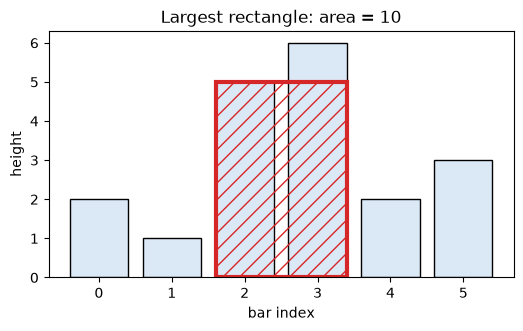

In [24]:
def largest_rectangle(heights):
    '''Return (area, left, right, height) of the largest rectangle in the histogram.'''
    hs = heights + [0]                          # sentinel forces all bars off the stack at the end
    stack, best = [], (0, 0, -1, 0)
    for i, h in enumerate(hs):
        while stack and hs[stack[-1]] >= h:     # bar on top cannot extend past i-1
            top = stack.pop()
            left = stack[-1] + 1 if stack else 0    # it extends left to just after the new top
            area = hs[top] * (i - left)
            if area > best[0]:
                best = (area, left, i - 1, hs[top])
        stack.append(i)
    return best

def largest_rectangle_brute(heights):
    best = 0
    for i in range(len(heights)):
        m = float("inf")
        for j in range(i, len(heights)):
            m = min(m, heights[j]); best = max(best, m * (j - i + 1))
    return best

bars = [2, 1, 5, 6, 2, 3]
area, left, right, height = largest_rectangle(bars)
print(f"largest rectangle in {bars}: area {area} (bars {left}..{right}, height {height})")
rng = random.Random(10)
for _ in range(2000):
    a = [rng.randint(0, 10) for _ in range(rng.randint(0, 25))]
    assert largest_rectangle(a)[0] == largest_rectangle_brute(a)
print("largest_rectangle matches the O(n^2) brute force on 2000 random histograms")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(range(len(bars)), bars, color="#dbe9f6", edgecolor="black")
ax.add_patch(Rectangle((left - 0.4, 0), right - left + 0.8, height, fill=False, edgecolor="tab:red", lw=3, hatch="//"))
ax.set_xlabel("bar index"); ax.set_ylabel("height"); ax.set_title(f"Largest rectangle: area = {area}")
plt.show()

**What just happened?** For `[2, 1, 5, 6, 2, 3]` the best rectangle has height 5 over bars 2 to 3 (area 10), drawn in red. Both monotonic-stack algorithms matched brute force on thousands of random inputs.

### 6.7 Min-stack design

**Problem:** a stack that also returns the current minimum in O(1). **Trick:** store with each item the minimum *of the stack up to and including it*. When we pop, the previous minimum is automatically back on top.

| op | stack of (value, min so far) | get_min |
|---|---|---|
| push 5 | (5,5) | 5 |
| push 3 | (5,5) (3,3) | 3 |
| push 7 | (5,5) (3,3) (7,3) | 3 |
| pop | (5,5) (3,3) | 3 |
| pop | (5,5) | 5 |

In [25]:
class MinStack:
    def __init__(self):
        self._items = []                        # list of (value, minimum of the stack up to here)

    def push(self, x):
        current_min = min(x, self._items[-1][1]) if self._items else x
        self._items.append((x, current_min))

    def pop(self):
        return self._items.pop()[0]

    def top(self):
        return self._items[-1][0]

    def get_min(self):                          # O(1): read it from the top pair
        return self._items[-1][1]


ms = MinStack()
for x in [5, 3, 7]:
    ms.push(x)
print("min after pushing 5, 3, 7:", ms.get_min()); ms.pop(); ms.pop(); print("min after two pops:", ms.get_min())

rng = random.Random(12)
ms, ref = MinStack(), []
for _ in range(5000):
    if ref and rng.random() < 0.4:
        assert ms.pop() == ref.pop()
    else:
        x = rng.randint(-50, 50); ms.push(x); ref.append(x)
    if ref:
        assert ms.get_min() == min(ref) and ms.top() == ref[-1]
print("MinStack.get_min() equals min(list) after each of 5000 random operations")

min after pushing 5, 3, 7: 3
min after two pops: 5


MinStack.get_min() equals min(list) after each of 5000 random operations


**What just happened?** All operations are O(1) time; space is O(n) (one extra number per item). A space-saving variant keeps a second stack that only stores a new value when it is ≤ the current minimum.

<a id="queues"></a>
## 7. Queues

> **In plain English:** a queue is a waiting line: first come, first served, with a few useful variations.

### 7.1 Intuition and definition

A queue at a coffee shop: people join at the **back (rear)** and are served from the **front**. First come, first served.

A **queue** is a collection with **FIFO** (First In, First Out) order:
- `enqueue(x)` adds x at the rear, O(1);
- `dequeue()` removes and returns the front item, O(1) (error if empty: **underflow**);
- `peek()` / `front()`, `is_empty()`, `len()`.

```
 dequeue <-  [ 10 | 20 | 30 | 40 ]  <- enqueue
            front            rear
```

⚠️ **Common mistake:** using a Python list with `list.pop(0)` as a queue. Each `pop(0)` shifts every remaining element, so it is **O(n)**. Use `collections.deque.popleft()` (O(1)), as the quick timing below shows.

In [26]:
class LinkedQueue:
    '''Queue on a singly linked list: dequeue at the head, enqueue at the tail.'''
    def __init__(self):
        self.head = self.tail = None
        self.size = 0

    def enqueue(self, x):                       # O(1)
        node = Node(x)
        if self.tail is None:
            self.head = self.tail = node
        else:
            self.tail.next = node
            self.tail = node
        self.size += 1

    def dequeue(self):                          # O(1)
        if self.head is None:
            raise IndexError("dequeue from empty queue")
        x, self.head = self.head.value, self.head.next
        if self.head is None:
            self.tail = None
        self.size -= 1
        return x

    def peek(self): return self.head.value
    def is_empty(self): return self.size == 0
    def __len__(self): return self.size


q = LinkedQueue()
for x in [10, 20, 30]:
    q.enqueue(x)
print("dequeue ->", q.dequeue(), "| front is now", q.peek(), "| size", len(q))

n = 50_000
lst, dq = list(range(n)), deque(range(n))
t0 = time.perf_counter()
while lst: lst.pop(0)                           # O(n) each
t_list = time.perf_counter() - t0
t0 = time.perf_counter()
while dq: dq.popleft()                          # O(1) each
t_deque = time.perf_counter() - t0
print(f"emptying {n:,} items from the front: list.pop(0) is {t_list / t_deque:.0f}x slower than deque.popleft()")

dequeue -> 10 | front is now 20 | size 2


emptying 50,000 items from the front: list.pop(0) is 48x slower than deque.popleft()


### 7.2 Circular queue (ring buffer) on a fixed array

With a plain array, dequeuing from the front leaves empty slots at the start that are never reused. A **circular queue** treats the array as a ring: indices wrap around with `% capacity`. We store `front` (index of the first item) and `size`; the rear slot is `(front + size) % capacity`.

Hand trace with capacity 5 (`_` = empty slot, F = front):

| operation | array | front | size |
|---|---|---|---|
| enqueue 10, 20, 30 | `[10, 20, 30, _, _]` | 0 | 3 |
| dequeue → 10, dequeue → 20 | `[_, _, 30, _, _]` | 2 | 1 |
| enqueue 40, 50, 60 | `[60, _, 30, 40, 50]` | 2 | 4 (60 wrapped round to index 0) |
| enqueue 70 | `[60, 70, 30, 40, 50]` | 2 | 5 (full) |
| enqueue 80 | error: queue is full (**overflow**) | | |

This is how audio buffers, network-card buffers, keyboard buffers and logging "last N events" are implemented.

In [27]:
class CircularQueue:
    def __init__(self, capacity):
        self.data = [None] * capacity           # fixed-size array
        self.capacity = capacity
        self.front = 0                          # index of the first item
        self.size = 0

    def is_empty(self): return self.size == 0
    def is_full(self): return self.size == self.capacity
    def __len__(self): return self.size

    def enqueue(self, x):
        if self.is_full():
            raise OverflowError("queue is full")
        rear = (self.front + self.size) % self.capacity   # wrap around the end of the array
        self.data[rear] = x
        self.size += 1

    def dequeue(self):
        if self.is_empty():
            raise IndexError("dequeue from empty queue")
        x = self.data[self.front]
        self.data[self.front] = None
        self.front = (self.front + 1) % self.capacity      # front also wraps
        self.size -= 1
        return x

    def peek(self):
        if self.is_empty():
            raise IndexError("peek from empty queue")
        return self.data[self.front]

    def items(self):                            # items in FIFO order
        return [self.data[(self.front + i) % self.capacity] for i in range(self.size)]


cq, rows = CircularQueue(5), []
def log(op):
    rows.append({"operation": op, "array": ["_" if v is None else v for v in cq.data], "front": cq.front, "size": cq.size})
for x in (10, 20, 30): cq.enqueue(x)
log("enqueue 10, 20, 30")
cq.dequeue(); cq.dequeue(); log("dequeue x2")
for x in (40, 50, 60): cq.enqueue(x)
log("enqueue 40, 50, 60")
cq.enqueue(70); log("enqueue 70")
try:
    cq.enqueue(80)                              # deliberate error: the queue is full
except OverflowError as e:
    rows.append({"operation": "enqueue 80", "array": f"caught OverflowError: {e}", "front": cq.front, "size": cq.size})
display(pd.DataFrame(rows))
print("FIFO order:", cq.items())

rng = random.Random(13)
for _ in range(50):
    cap = rng.randint(1, 8); cq, ref = CircularQueue(cap), deque()
    for _ in range(500):
        if rng.random() < 0.5:
            if len(ref) == cap:
                try: cq.enqueue(0); raise AssertionError("should be full")
                except OverflowError: pass
            else:
                x = rng.randint(0, 99); cq.enqueue(x); ref.append(x)
        elif ref:
            assert cq.dequeue() == ref.popleft()
        assert cq.items() == list(ref)
print("CircularQueue matches deque on 50 x 500 random operations (including overflow)")

,operation,array,front,size
0,"enqueue 10, 20, 30","[10, 20, 30, _, _]",0,3
1,dequeue x2,"[_, _, 30, _, _]",2,1
2,"enqueue 40, 50, 60","[60, _, 30, 40, 50]",2,4
3,enqueue 70,"[60, 70, 30, 40, 50]",2,5
4,enqueue 80,caught OverflowError: queue is full,2,5


FIFO order: [30, 40, 50, 60, 70]


CircularQueue matches deque on 50 x 500 random operations (including overflow)


**What just happened?** The table matches the hand trace: after two dequeues the front moved to index 2, 60 wrapped round to index 0, and enqueueing 80 into a full queue raised `OverflowError`. All operations are O(1) time; space is O(capacity) and never grows.

🎓 **Exam / interview tip:** many textbooks implement the circular queue with only `front` and `rear` indices and declare it full when `(rear + 1) % capacity == front`. That version **wastes one slot** to tell "full" from "empty". Keeping a `size` counter (as here) avoids the wasted slot.

### 7.3 Priority queue: a preview of heaps

A **priority queue** serves the item with the **highest priority** (or smallest key) first, not the oldest. Example: a hospital emergency room treats the most urgent patient first. Three ways to build one:

| Implementation | insert | extract-min | notes |
|---|---|---|---|
| Unsorted list | O(1) | O(n) (scan for the minimum) | fine for tiny n |
| Sorted list (`bisect.insort`) | O(n) (shifting) | O(1) (pop from the end) | |
| **Binary heap** (`heapq`) | **O(log n)** | **O(log n)** | the standard choice; built from scratch in the next notebook |

In [28]:
patients = [("broken arm", 3), ("heart attack", 1), ("headache", 5), ("stroke", 1), ("sprained ankle", 4)]  # lower = more urgent

class UnsortedPQ:
    def __init__(self): self.items = []
    def push(self, priority, order, item): self.items.append((priority, order, item))   # O(1)
    def pop(self):                                                       # O(n) scan for the minimum
        i = min(range(len(self.items)), key=lambda j: self.items[j])
        return self.items.pop(i)[2]

class SortedPQ:
    def __init__(self): self.items = []
    def push(self, priority, order, item): bisect.insort(self.items, (-priority, -order, item))  # O(n); smallest priority at the END
    def pop(self): return self.items.pop()[2]                            # O(1)

class HeapPQ:
    def __init__(self): self.items = []
    def push(self, priority, order, item): heapq.heappush(self.items, (priority, order, item))    # O(log n)
    def pop(self): return heapq.heappop(self.items)[2]                   # O(log n)

for PQ in (UnsortedPQ, SortedPQ, HeapPQ):
    pq = PQ()
    for order, (name, pr) in enumerate(patients):
        pq.push(pr, order, name)               # `order` breaks ties: first arrival first (FIFO among equals)
    print(f"{PQ.__name__:10}:", [pq.pop() for _ in patients])

UnsortedPQ: ['heart attack', 'stroke', 'broken arm', 'sprained ankle', 'headache']
SortedPQ  : ['heart attack', 'stroke', 'broken arm', 'sprained ankle', 'headache']
HeapPQ    : ['heart attack', 'stroke', 'broken arm', 'sprained ankle', 'headache']


**What just happened?** All three give the same treatment order: heart attack and stroke (priority 1, in arrival order), then broken arm, sprained ankle and headache. The `order` counter is a standard trick: it breaks ties in arrival order and also stops Python from ever comparing the items themselves. Heaps are explained in detail in the next notebook.

### 7.4 `collections.deque`

A **deque** ("deck", *double-ended queue*) allows O(1) insertion and removal at **both** ends. Python's `collections.deque` is implemented in C as a doubly linked list of fixed-size blocks, so it is both fast and memory-efficient. It can act as a stack, a queue, or a bounded "last N items" buffer (`maxlen`).

| Operation | `deque` | `list` |
|---|---|---|
| `append` / `pop` (right end) | O(1) | amortised O(1) |
| `appendleft` / `popleft` (left end) | **O(1)** | O(n) |
| index `d[i]` in the middle | O(n) | **O(1)** |
| `rotate(k)` | O(k) | O(n) |

In [29]:
d = deque([1, 2, 3])
d.appendleft(0); d.append(4)
print("after appendleft(0), append(4):", d)
print("popleft ->", d.popleft(), "| pop ->", d.pop(), "| now:", d)
d.rotate(1); print("rotate(1):", d)                       # last element moves to the front
last3 = deque(maxlen=3)                                   # a bounded buffer: old items fall off automatically
for reading in [21.0, 21.5, 22.1, 23.4, 22.8]:
    last3.append(reading)
print("last 3 sensor readings:", list(last3))

after appendleft(0), append(4): deque([0, 1, 2, 3, 4])
popleft -> 0 | pop -> 4 | now: deque([1, 2, 3])
rotate(1): deque([3, 1, 2])
last 3 sensor readings: [22.1, 23.4, 22.8]


### 7.5 Deque application: sliding-window maximum

**Problem:** for every window of k consecutive numbers, report the maximum. The brute force is O(n·k). With a **monotonic deque** it is **O(n)**: keep indices whose values are **decreasing** from front to back.
1. Drop the front index if it has slid out of the window.
2. Pop from the back every index whose value is ≤ the new value (they can never be a maximum again: the new value is bigger *and* stays longer).
3. Push the new index. The front of the deque is the maximum of the current window.

Trace for `[1, 3, -1, -3, 5, 3, 6, 7]`, k = 3:

result: [3, 3, 5, 5, 6, 7]


,i,x,deque (values),window,max
0,0,1,[1],[1],
1,1,3,[3],"[1, 3]",
2,2,-1,"[3, -1]","[1, 3, -1]",3
3,3,-3,"[3, -1, -3]","[3, -1, -3]",3
4,4,5,[5],"[-1, -3, 5]",5
5,5,3,"[5, 3]","[-3, 5, 3]",5
6,6,6,[6],"[5, 3, 6]",6
7,7,7,[7],"[3, 6, 7]",7


matches brute force on 1000 random arrays and pandas .rolling(20).max() on a 300-point series


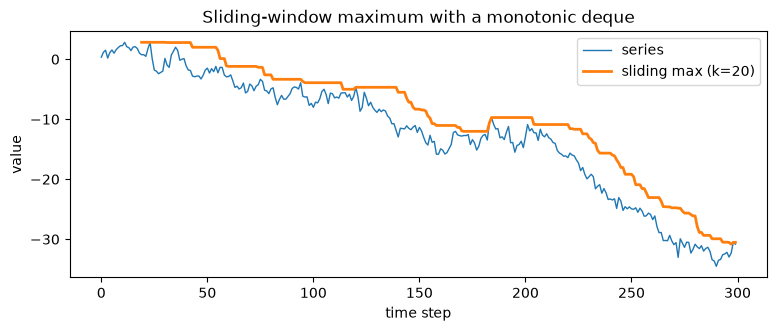

In [30]:
def sliding_window_max(nums, k, trace=None):
    dq, out = deque(), []                                  # dq holds indices; nums[dq] is decreasing
    for i, x in enumerate(nums):
        if dq and dq[0] <= i - k:                          # 1. front index left the window
            dq.popleft()
        while dq and nums[dq[-1]] <= x:                    # 2. smaller values can never be the max again
            dq.pop()
        dq.append(i)                                       # 3. add the new index
        if i >= k - 1:
            out.append(nums[dq[0]])                        # front = max of window [i-k+1, i]
        if trace is not None:
            trace.append({"i": i, "x": x, "deque (values)": [nums[j] for j in dq],
                          "window": nums[max(0, i - k + 1): i + 1], "max": nums[dq[0]] if i >= k - 1 else ""})
    return out

rows = []
print("result:", sliding_window_max([1, 3, -1, -3, 5, 3, 6, 7], 3, rows))
display(pd.DataFrame(rows))

rng = random.Random(14)
for _ in range(1000):
    a = [rng.randint(-20, 20) for _ in range(rng.randint(1, 40))]
    k = rng.randint(1, len(a))
    assert sliding_window_max(a, k) == [max(a[i:i + k]) for i in range(len(a) - k + 1)]
series = np.cumsum(np.random.default_rng(1).normal(size=300))   # a random-walk "price" series
ours = sliding_window_max(list(series), 20)
pandas_max = pd.Series(series).rolling(20).max().dropna().to_numpy()
assert np.allclose(ours, pandas_max)
print("matches brute force on 1000 random arrays and pandas .rolling(20).max() on a 300-point series")

plt.figure(figsize=(9, 3.2))
plt.plot(series, label="series", lw=1)
plt.plot(range(19, 300), ours, label="sliding max (k=20)", lw=2)
plt.xlabel("time step"); plt.ylabel("value"); plt.title("Sliding-window maximum with a monotonic deque"); plt.legend(); plt.show()

**What just happened?** The answer is `[3, 3, 5, 5, 6, 7]`. The "deque (values)" column is always decreasing, and its first element is the window maximum. Each index enters and leaves the deque at most once, so the whole scan is O(n) time and O(k) space. The result also matches pandas' `rolling(20).max()`, which computes the same rolling-window feature that forecasting models use.

<a id="queue-apps"></a>
## 8. Queue applications

> **In plain English:** queues show up whenever things must be handled in arrival order: exploring a network, sharing a CPU, reading a stream.

### 8.1 BFS preview: who is how many handshakes away?

**Breadth-first search (BFS)** explores a network in "rings": first all direct friends, then friends of friends, and so on. A FIFO queue guarantees that people at distance d are processed before anyone at distance d + 1. Graphs get a full treatment in notebook 07.

In [31]:
friends = {
    "Ana": ["Ben", "Cai"], "Ben": ["Ana", "Dev", "Eli"], "Cai": ["Ana", "Eli"],
    "Dev": ["Ben", "Fay"], "Eli": ["Ben", "Cai", "Fay"], "Fay": ["Dev", "Eli", "Gus"], "Gus": ["Fay"],
}

def bfs_hops(graph, start):
    dist = {start: 0}
    queue = deque([start])
    rows = []
    while queue:
        person = queue.popleft()                    # FIFO: the oldest discovered person first
        for friend in graph[person]:
            if friend not in dist:                  # first time we see them = shortest distance
                dist[friend] = dist[person] + 1
                queue.append(friend)
        rows.append({"dequeued": person, "queue after": list(queue)})
    return dist, rows

dist, rows = bfs_hops(friends, "Ana")
display(pd.DataFrame(rows))
print("hops from Ana:", dist)

,dequeued,queue after
0,Ana,"[Ben, Cai]"
1,Ben,"[Cai, Dev, Eli]"
2,Cai,"[Dev, Eli]"
3,Dev,"[Eli, Fay]"
4,Eli,[Fay]
5,Fay,[Gus]
6,Gus,[]


hops from Ana: {'Ana': 0, 'Ben': 1, 'Cai': 1, 'Dev': 2, 'Eli': 2, 'Fay': 3, 'Gus': 4}


**What just happened?** Ana's friends Ben and Cai are 1 hop away, Dev and Eli 2, Fay 3 and Gus 4. Each person is enqueued and dequeued once, and each friendship is looked at twice, so BFS is O(V + E).

### 8.2 Task scheduling: round-robin CPU scheduling

Operating systems share one CPU between many processes. **Round robin** gives each process a fixed **time quantum**; if it is not finished it goes to the **back of the queue**. This is a circular use of a FIFO queue. Here 4 processes all arrive at time 0, quantum = 2.

,burst,completion,turnaround,waiting
P1,5,13,13,8
P2,3,10,10,7
P3,1,5,5,4
P4,4,12,12,8


average waiting time: 6.75


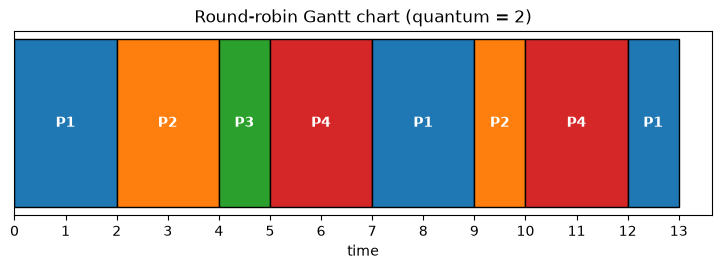

In [32]:
def round_robin(bursts, quantum):
    queue = deque(bursts.items())                       # (name, remaining time)
    t, timeline, finish = 0, [], {}
    while queue:
        name, remaining = queue.popleft()
        run = min(quantum, remaining)
        timeline.append((name, t, run))                 # (process, start, duration) for the Gantt chart
        t += run
        if remaining > run:
            queue.append((name, remaining - run))       # not finished: back of the queue
        else:
            finish[name] = t
    return timeline, finish

bursts = {"P1": 5, "P2": 3, "P3": 1, "P4": 4}
timeline, finish = round_robin(bursts, quantum=2)
table = pd.DataFrame({"burst": bursts, "completion": finish})
table["turnaround"] = table["completion"]               # all arrive at t = 0
table["waiting"] = table["turnaround"] - table["burst"]
display(table)
print("average waiting time:", table["waiting"].mean())
assert max(finish.values()) == sum(bursts.values())     # the CPU is never idle

fig, ax = plt.subplots(figsize=(9, 2.4))
colours = dict(zip(bursts, plt.cm.tab10.colors))
for name, start, dur in timeline:
    ax.barh(0, dur, left=start, color=colours[name], edgecolor="black")
    ax.text(start + dur / 2, 0, name, ha="center", va="center", color="white", fontweight="bold")
ax.set_yticks([]); ax.set_xlabel("time"); ax.set_title("Round-robin Gantt chart (quantum = 2)")
ax.set_xticks(range(0, sum(bursts.values()) + 1)); plt.show()

**What just happened?** The Gantt chart shows the queue rotating: P1, P2, P3, P4, P1, P2, P4, P1. P3 needs only 1 unit and finishes at time 5; P1 is last at time 13. The table shows completion and waiting times (average waiting time 6.75 units). A smaller quantum makes the system more responsive but adds more context-switching overhead.

### 8.3 Streaming: first non-repeating character

Characters arrive one by one; after each one, report the first character so far that has appeared exactly once (or `#`). Keep a **count** per character and a **queue** of candidates; pop from the front while the front's count is > 1. Each character is enqueued and dequeued at most once: amortised O(1) per character.

In [33]:
def first_non_repeating(stream):
    counts, queue, out = Counter(), deque(), []
    for ch in stream:
        counts[ch] += 1
        if counts[ch] == 1:
            queue.append(ch)                            # a new candidate joins at the back
        while queue and counts[queue[0]] > 1:           # front repeated: it can never be the answer again
            queue.popleft()
        out.append(queue[0] if queue else "#")
    return "".join(out)

def first_non_repeating_brute(stream):
    out = []
    for i in range(1, len(stream) + 1):
        prefix = stream[:i]
        out.append(next((c for c in prefix if prefix.count(c) == 1), "#"))
    return "".join(out)

print("aabcbc ->", first_non_repeating("aabcbc"))
rng = random.Random(15)
for _ in range(2000):
    s = "".join(rng.choice("abcd") for _ in range(rng.randint(0, 20)))
    assert first_non_repeating(s) == first_non_repeating_brute(s)
print("matches brute force on 2000 random streams")

aabcbc -> a#bbc#
matches brute force on 2000 random streams


**What just happened?** For `aabcbc` the answers after each character are `a # b b c #`: after `aa` nothing is unique; `b` is the first unique character until it repeats, then `c`, and finally nothing.

### 8.4 A queue from two stacks, and a stack from a queue

**Queue with two stacks:** push onto an `inbox` stack; to dequeue, pop from an `outbox` stack, and only when the outbox is empty pour the whole inbox into it (which reverses the order, so the oldest item ends up on top). Each item is moved at most once, so operations are **amortised O(1)**.

**Stack with one queue:** after enqueueing a new item, rotate the queue (dequeue and re-enqueue) `len − 1` times so the newest item is at the front. Push is O(n), pop is O(1). (With two queues you can choose to make pop O(n) instead.)

In [34]:
class QueueFromStacks:
    def __init__(self):
        self.inbox, self.outbox, self.moves = [], [], 0
    def enqueue(self, x):
        self.inbox.append(x)                            # O(1)
    def dequeue(self):
        if not self.outbox:                             # only refill when the outbox is empty
            while self.inbox:
                self.outbox.append(self.inbox.pop())    # reverses the order: oldest on top
                self.moves += 1
        if not self.outbox:
            raise IndexError("dequeue from empty queue")
        return self.outbox.pop()
    def __len__(self): return len(self.inbox) + len(self.outbox)


class StackFromQueue:
    def __init__(self):
        self.q = deque()                                # used only with append (enqueue) and popleft (dequeue)
    def push(self, x):
        self.q.append(x)
        for _ in range(len(self.q) - 1):                # rotate so x is at the front
            self.q.append(self.q.popleft())
    def pop(self):
        return self.q.popleft()
    def __len__(self): return len(self.q)


rng = random.Random(16)
qs, ref, n_enq = QueueFromStacks(), deque(), 0
for _ in range(20_000):
    if ref and rng.random() < 0.5:
        assert qs.dequeue() == ref.popleft()
    else:
        x = rng.random(); qs.enqueue(x); ref.append(x); n_enq += 1
print(f"QueueFromStacks matches deque; {n_enq:,} enqueues caused {qs.moves:,} stack-to-stack moves (<= 1 per item)")

ss, ref = StackFromQueue(), []
for _ in range(3000):
    if ref and rng.random() < 0.5:
        assert ss.pop() == ref.pop()
    else:
        x = rng.random(); ss.push(x); ref.append(x)
print("StackFromQueue matches a Python list on 3000 random operations")

QueueFromStacks matches deque; 10,070 enqueues caused 9,998 stack-to-stack moves (<= 1 per item)
StackFromQueue matches a Python list on 3000 random operations


**What just happened?** The number of moves between the two stacks never exceeds the number of enqueued items, which is the *amortised* argument in numbers: some dequeues are expensive (pouring), but in total each item is moved at most once.

🎓 **Exam / interview tip:** "Implement a queue using stacks" is asked to test whether you can explain **amortised** complexity. Say: "worst case O(n) for a single dequeue, but O(1) amortised, because each element is pushed and popped at most twice in total."

<a id="summary"></a>
## 9. Complexity summary

> **In plain English:** one table with the speed of every operation in this notebook, for quick revision.

| Structure / operation | Time | Space | Notes |
|---|---|---|---|
| Singly linked list: push/pop front | O(1) | O(n) total | |
| Singly linked list: push back (with tail) | O(1) | | pop back is O(n) |
| Singly linked list: access / search | O(n) | | no random access |
| Doubly linked list: push/pop both ends, delete given node | O(1) | O(n), 2 pointers/node | |
| Circular list: rotate by 1 | O(1) | | |
| Reverse / Floyd / middle / merge / remove n-th | O(n) | O(1) | recursive reverse uses O(n) stack |
| LRU cache get/put | O(1) average | O(C) | dict + doubly linked list |
| LFU cache get/put | O(1) average | O(C) | dict + frequency buckets |
| Stack push/pop/peek (array) | amortised O(1) | O(n) | worst case O(n) during a resize |
| Stack push/pop/peek (linked) | O(1) worst case | O(n) | |
| Balanced brackets, shunting-yard, postfix eval | O(n) | O(n) | each token pushed/popped once |
| Monotonic stack (NGE, histogram) | O(n) | O(n) | |
| Min-stack get_min | O(1) | O(n) | |
| Queue (linked or circular array) enqueue/dequeue | O(1) | O(n) / O(capacity) | |
| Priority queue (binary heap) insert / extract | O(log n) | O(n) | next notebook |
| Deque operations at the ends | O(1) | O(n) | |
| Sliding-window maximum | O(n) | O(k) | monotonic deque |
| Queue from two stacks | amortised O(1) | O(n) | |
| Stack from one queue (push / pop) | O(n) / O(1) | O(n) | |

<a id="modern-ai"></a>
## 10. 🔗 How this connects to modern AI

> **In plain English:** the same simple structures sit inside LLM servers, reinforcement-learning agents and data pipelines.

- **LRU caches in AI systems.** LLM serving engines cache prompt prefixes and their key/value tensors and evict old entries with LRU-style policies; embedding and API-response caches use `functools.lru_cache` or Redis with LRU eviction. See [LLM inference optimisation](../../08_LLM/13_inference_optimization.ipynb).
- **Queues in model serving.** Inference servers put incoming requests in a queue and form batches from it (dynamic / continuous batching); background jobs in ML APIs use task queues. See [ML serving with FastAPI](../../12_FastAPI/03_ml_serving_with_fastapi.ipynb).
- **Deques as replay buffers.** DQN-style reinforcement learning stores the last N transitions in a `deque(maxlen=N)` and samples mini-batches from it. See [Deep Q-Networks](../../11_Reinforcement_Learning/04_deep_q_networks.ipynb).
- **Sliding windows over time series.** Rolling maximum/mean features (exactly the deque trick above) are standard inputs to forecasting and anomaly-detection models. See [time-series basics](../../04_Forecasting/01_time_series_basics.ipynb).
- **Stacks in parsing and autodiff.** Tokenisers, JSON/function-call parsers for LLM tool use, and expression evaluators use stacks; reverse-mode autodiff (backpropagation) replays operations in reverse order, i.e. LIFO, from a recorded "tape". See [structured outputs](../../08_LLM/17_structured_outputs.ipynb) and [neural-network fundamentals](../../05_Deep_Learning/01_neural_network_fundamentals.ipynb).
- **BFS with a queue** is the backbone of uninformed search in classical AI planning and of graph exploration in agents and knowledge graphs (notebook 07 of this module).

<a id="recap"></a>
## 11. Recap

> **In plain English:** the key ideas in a few bullets, then practice problems to check you really understood them.

- A **linked list** stores elements in nodes connected by pointers: O(1) insertion/deletion where you already stand, but O(n) access by position. **Singly** (next), **doubly** (prev + next, O(1) delete of a known node) and **circular** (no end) variants exist. **Sentinel** nodes remove special cases.
- The core linked-list techniques are **pointer re-wiring in the right order**, **dummy nodes**, and **slow/fast pointers** (Floyd's cycle detection, middle, n-th from end).
- **Arrays** win on random access and cache locality; **linked lists** win when you hold node references and insert/delete a lot.
- **LRU cache = hash map + doubly linked list**, O(1) per operation; `OrderedDict` and `functools.lru_cache` are the built-in equivalents. **LFU** evicts by frequency using frequency buckets.
- A **stack** is LIFO. It powers bracket matching, the **shunting-yard** algorithm and **postfix evaluation**, undo/redo, the **call stack** (recursion), **monotonic-stack** problems and the **min-stack**.
- A **queue** is FIFO; the **circular queue** reuses a fixed array with `% capacity`; a **priority queue** serves the smallest key first (heaps, next notebook); a **deque** is O(1) at both ends and gives the O(n) **sliding-window maximum**.
- Queues drive **BFS**, **round-robin scheduling** and **stream processing**; a queue can be built from two stacks in amortised O(1).

## Practice problems

**1. (Easy, conceptual)** Give the time complexity of: (a) deleting the last node of a singly linked list with a tail pointer; (b) deleting the last node of a doubly linked list; (c) `list.insert(0, x)` on a Python list of n elements.

<details><summary>Show solution</summary>

(a) **O(n)**: the tail pointer tells you where the last node is, but you need the node *before* it to set its `next` to `None`, and a singly linked list can only reach it by walking from the head. (b) **O(1)**: `tail.prev` gives the previous node directly. (c) **O(n)**: every existing element shifts one position to the right.
</details>

**2. (Easy, coding)** Remove duplicates from a **sorted** singly linked list, so that every value appears once (e.g. `1 → 1 → 2 → 3 → 3` becomes `1 → 2 → 3`). O(n) time, O(1) space.

<details><summary>Show solution</summary>

```python
def delete_duplicates(head):
    node = head
    while node is not None and node.next is not None:
        if node.next.value == node.value:
            node.next = node.next.next      # skip the duplicate, stay on the same node
        else:
            node = node.next
    return head
```
Because the list is sorted, duplicates are adjacent; when the next node repeats the current value we bypass it and stay put. (Tested on 500 random sorted lists.)
</details>

**3. (Medium, conceptual)** A circular queue of capacity 4 (with a `size` counter) starts empty with `front = 0`. Perform: enqueue A, enqueue B, enqueue C, dequeue, dequeue, enqueue D, enqueue E, enqueue F. Give the array contents, `front` and `size` at the end. What happens if you now enqueue G?

<details><summary>Show solution</summary>

After A, B, C: `[A, B, C, _]`, front 0, size 3. Two dequeues (A, B): `[_, _, C, _]`, front 2, size 1. Enqueue D goes to index (2+1)%4 = 3, E to (2+2)%4 = 0, F to (2+3)%4 = 1: final array `[E, F, C, D]`, **front = 2, size = 4** (FIFO order C, D, E, F). The queue is full, so enqueue G raises an **overflow** error.
</details>

**4. (Medium, coding)** Check whether a singly linked list is a palindrome in O(n) time and **O(1)** extra space.

<details><summary>Show solution</summary>

Find the middle with slow/fast pointers, reverse the second half in place, then compare the two halves.
```python
def is_palindrome(head):
    # 1. find the middle (slow ends at the start of the second half)
    slow = fast = head
    while fast is not None and fast.next is not None:
        slow, fast = slow.next, fast.next.next
    # 2. reverse the second half in place
    prev = None
    while slow is not None:
        slow.next, prev, slow = prev, slow, slow.next
    # 3. compare the first half with the reversed second half
    left, right = head, prev
    while right is not None:
        if left.value != right.value:
            return False
        left, right = left.next, right.next
    return True
```
(Tested against `v == v[::-1]` on 2,000 random lists. In production you would reverse the second half back afterwards to restore the input.)
</details>

**5. (Medium, coding)** *Daily temperatures:* for each day, how many days until a warmer temperature (0 if never)? `[73, 74, 75, 71, 69, 72, 76, 73]` → `[1, 1, 4, 2, 1, 1, 0, 0]`. Aim for O(n).

<details><summary>Show solution</summary>

A monotonic stack of indices, exactly like the next-greater-element problem, but store the *distance* instead of the value.
```python
def daily_temperatures(temps):
    answer = [0] * len(temps)
    stack = []                                  # indices of days still waiting for a warmer day
    for i, t in enumerate(temps):
        while stack and temps[stack[-1]] < t:
            j = stack.pop()
            answer[j] = i - j                   # days waited
        stack.append(i)
    return answer
```
</details>

**6. (Hard, coding)** Design a queue with `enqueue`, `dequeue` and `get_max`, all amortised O(1).

<details><summary>Show solution</summary>

Keep the real queue plus a monotonic deque of "maximum candidates" (non-increasing). This is the sliding-window-maximum idea where the window is "whatever is currently in the queue".
```python
from collections import deque

class MaxQueue:
    def __init__(self):
        self.items = deque()                    # the real FIFO contents
        self.maxes = deque()                    # decreasing candidates for the maximum
    def enqueue(self, x):
        self.items.append(x)
        while self.maxes and self.maxes[-1] < x:    # keep equal values (they may be dequeued separately)
            self.maxes.pop()
        self.maxes.append(x)
    def dequeue(self):
        x = self.items.popleft()
        if x == self.maxes[0]:
            self.maxes.popleft()
        return x
    def get_max(self):
        return self.maxes[0]
```
(Tested against `max(queue)` on 5,000 random operations.)
</details>

**7. (Hard, coding)** Two singly linked lists may merge at some node and share their tail (a Y shape). Return the first shared node (or `None`) in O(m + n) time and O(1) space.

<details><summary>Show solution</summary>

Walk pointer `p` through A then B, and `q` through B then A. Both travel `len(A) + len(B)` steps at most, so they line up and meet at the intersection (or both reach `None` together).
```python
def intersection_node(a, b):
    p, q = a, b
    while p is not q:                           # each pointer walks A then B (or B then A)
        p = p.next if p is not None else b
        q = q.next if q is not None else a
    return p                                    # the shared node, or None after len(A)+len(B) steps
```
</details>

## Further reading

- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms* (CLRS), 4th ed. (2022): Ch. 10 "Elementary Data Structures" (stacks, queues, linked lists) and Ch. 16 "Amortized Analysis" (Ch. 17 in the 3rd ed.).
- Goodrich, Tamassia, Goldwasser, *Data Structures and Algorithms in Python* (2013): Ch. 6 "Stacks, Queues, and Deques" and Ch. 7 "Linked Lists".
- Sedgewick and Wayne, *Algorithms*, 4th ed.: §1.3 "Bags, Queues, and Stacks" (free companion site: algs4.cs.princeton.edu).
- Pat Morin, *Open Data Structures* (free online textbook, opendatastructures.org), chapters on array-based lists and linked lists.
- VisuAlgo (visualgo.net): animations of linked lists, stacks, queues and deques. GeeksforGeeks "Data Structures" tutorial for extra practice problems.

## Next notebook

➡️ [06 · Trees, Binary Search Trees and Heaps](06_trees_bst_and_heaps.ipynb): from linear structures to hierarchical ones, including the heap behind the priority queue you previewed here.